In [3]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


使用全部基因，TAD 矩阵形状: (32465, 298)
全局分割点 (threshold_norm): 0.3826

每个亚群每个 bin 的细胞数统计:
  TLD-2α: 总细胞=35, bin数=21, 平均=1.67 ± 0.99 (min=1, max=5)
  TLD-2β: 总细胞=22, bin数=17, 平均=1.29 ± 0.46 (min=1, max=2)
  TLD-4α: 总细胞=128, bin数=46, 平均=2.78 ± 6.34 (min=1, max=44)
  TLD-4β: 总细胞=58, bin数=23, 平均=2.52 ± 5.52 (min=1, max=28)

各曲线原始 x 和 y 范围（跳过第一个 bin 后，未插入起点）:
  TLD-2α: stage=2C, x_min=0.0050, x_max=0.3800, y_min=4.5783, y_max=100.0000, len=21
  TLD-2β: stage=2C, x_min=0.0600, x_max=0.3800, y_min=5.9927, y_max=100.0000, len=17
  TLD-4α: stage=4C, x_min=0.3800, x_max=1.0000, y_min=2.3117, y_max=100.0000, len=46
  TLD-4β: stage=4C, x_min=0.3800, x_max=1.0000, y_min=4.7403, y_max=100.0000, len=23

TLD-2α vs TLD-2β p = 0.010447844219839629
TLD-4α vs TLD-4β p = 0.9667338346656346


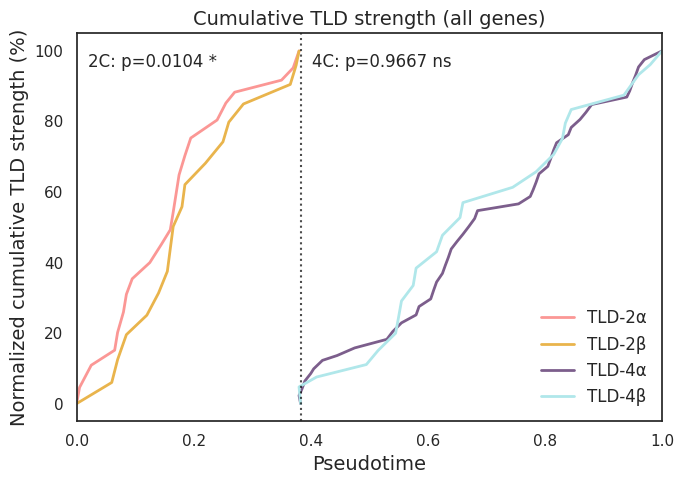

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
sns.set(style="white")

# ========== 全局参数 ==========
BIN_SIZE = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time_orig = 5.5

# ========== 1. 读取 TAD strength 数据（全部基因，不筛选） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')

tad_filtered = tad_strength.copy()
print(f"使用全部基因，TAD 矩阵形状: {tad_filtered.shape}")

# ========== 2. 读取时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

if len(sample_to_time) == 0:
    raise ValueError("时间映射为空，无法继续分析。")

all_times = np.array(list(sample_to_time.values()), dtype=float)
t_min_global = all_times.min()
t_max_global = all_times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time_orig - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 3. 读取亚群 ID ==========
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_2C_C1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_C2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_D1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_D2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

subgroups = {
    'TLD-2α': subgroup_2C_C1,
    'TLD-2β': subgroup_2C_C2,
    'TLD-4α': subgroup_4C_D1,
    'TLD-4β': subgroup_4C_D2
}

# ========== 4. 辅助函数：分箱累积曲线 ==========
def build_binned_curve(times, values, bin_size, skip_first=False):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_agg = (
        df.groupby('bin')
        .agg({'value': 'mean', 'time': 'count'})
        .reset_index()
        .sort_values('bin')
    )

    x = bin_agg['bin'].values
    v = bin_agg['value'].values
    counts = bin_agg['time'].values  # 每个 bin 的细胞数

    if skip_first and len(v) > 1:
        x = x[1:]
        v = v[1:]
        counts = counts[1:]

    if len(v) == 0:
        return np.array([]), np.array([]), np.array([])

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum, counts

# ========== 5. 构建曲线（亚群内独立归一化） ==========
curves = {}
bin_cell_counts = {}

for sg, cells in subgroups.items():
    # 修复：原代码 sg.startswith('2C') 永远为 False
    if sg.startswith('TLD-2'):
        stage = '2C'
        time_mask = lambda t: t <= min_time_orig
        skip_first = True
    else:
        stage = '4C'
        time_mask = lambda t: t >= min_time_orig
        skip_first = False

    valid_cells = [c for c in cells if c in tad_filtered.columns and c in sample_to_time]
    if not valid_cells:
        print(f"警告: {sg} 没有有效细胞")
        continue

    sub_data = tad_filtered[valid_cells]
    cell_means = sub_data.mean(axis=0)

    times_raw = np.array([float(sample_to_time[c]) for c in valid_cells])
    values = cell_means.values.astype(float)

    idx = np.argsort(times_raw)
    times_raw = times_raw[idx]
    values = values[idx]

    mask = time_mask(times_raw)
    times_raw = times_raw[mask]
    values = values[mask]

    if len(times_raw) == 0:
        print(f"警告: {sg} 在 {stage} 阶段没有有效细胞")
        continue

    t_min_sub = times_raw.min()
    t_max_sub = times_raw.max()

    if t_max_sub == t_min_sub:
        if stage == '2C':
            times_norm = np.full_like(times_raw, 0.0, dtype=float)
        else:
            times_norm = np.full_like(times_raw, 1.0, dtype=float)
    else:
        if stage == '2C':
            times_norm = threshold_norm * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)
        else:
            times_norm = threshold_norm + (1 - threshold_norm) * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)

    x, cum, counts = build_binned_curve(times_norm, values, BIN_SIZE, skip_first=skip_first)
    if len(x) == 0:
        continue

    curves[sg] = (x, cum, stage)
    bin_cell_counts[sg] = counts

# 检查曲线完整性
for sg in ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']:
    if sg not in curves:
        print(f"错误: {sg} 曲线缺失")

# 打印每个亚群每个 bin 的细胞数
print("\n每个亚群每个 bin 的细胞数统计:")
for sg in ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']:
    if sg in bin_cell_counts:
        counts = bin_cell_counts[sg]
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {sg}: 总细胞={total}, bin数={n_bins}, 平均={avg:.2f} ± {std:.2f} "
              f"(min={counts.min()}, max={counts.max()})")
    else:
        print(f"  {sg}: 无数据")

print("\n各曲线原始 x 和 y 范围（跳过第一个 bin 后，未插入起点）:")
for sg in ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']:
    if sg in curves:
        x, y, stage = curves[sg]
        print(f"  {sg}: stage={stage}, x_min={x.min():.4f}, x_max={x.max():.4f}, "
              f"y_min={y.min():.4f}, y_max={y.max():.4f}, len={len(x)}")
    else:
        print(f"  {sg}: 曲线缺失")

# ========== 6. 统计检验 ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

p_2c = np.nan
if 'TLD-2α' in curves and 'TLD-2β' in curves:
    x1, y1, _ = curves['TLD-2α']
    x2, y2, _ = curves['TLD-2β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_2c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

p_4c = np.nan
if 'TLD-4α' in curves and 'TLD-4β' in curves:
    x1, y1, _ = curves['TLD-4α']
    x2, y2, _ = curves['TLD-4β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_4c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

print(f"\nTLD-2α vs TLD-2β p = {p_2c}")
print(f"TLD-4α vs TLD-4β p = {p_4c}")

# ========== 7. 绘图 ==========
colors = {
    'TLD-2α': '#fb9795',
    'TLD-2β': '#E9B44C',
    'TLD-4α': '#7c5e8c',
    'TLD-4β': '#b0e7ea'
}

linestyles = {
    'TLD-2α': '-',
    'TLD-2β': '-',
    'TLD-4α': '-',
    'TLD-4β': '-'
}
labels = ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']

fig, ax = plt.subplots(figsize=(7, 5))

for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    ax.plot(x_plot, y_plot, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    return f"{label}: {format_p_value(p)} {sig_star(p)}"

ax.text(0.02, 0.95, format_p_text("2C", p_2c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)
ax.text(min(threshold_norm + 0.02, 0.98), 0.95, format_p_text("4C", p_4c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative TLD strength (%)', fontsize=14)
ax.set_title('Cumulative TLD strength (all genes)', fontsize=14)
ax.set_xlim(0, 1)
ax.legend(loc='lower right', fontsize=12, frameon=False)

plt.tight_layout()
plt.savefig('IVF_Cumulative_AllGenes_SubgroupNormalized.svg',
            dpi=300, bbox_inches='tight', transparent=True)

plt.show()

# 保存插入起点后的曲线数据
curve_records = []
for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    for xi, yi in zip(x_plot, y_plot):
        curve_records.append([sg, xi, yi])

curve_df = pd.DataFrame(curve_records, columns=["subgroup", "bin", "cumulative_percent"])
curve_df.to_csv("IVF_AllGenes_SubgroupNormalized_curves.csv", index=False)

[deTAD] 筛选 deboundary 基因后 TAD 矩阵形状: (3472, 298)
全局分割点 (threshold_norm): 0.3826

各曲线原始 x 和 y 范围（跳过第一个 bin 后，未插入起点）:
  TLD-2α: stage=2C, x_min=0.0050, x_max=0.3800, y_min=4.3425, y_max=100.0000, len=21
  TLD-2β: stage=2C, x_min=0.0600, x_max=0.3800, y_min=6.1141, y_max=100.0000, len=17
  TLD-4α: stage=4C, x_min=0.3800, x_max=1.0000, y_min=2.3699, y_max=100.0000, len=46
  TLD-4β: stage=4C, x_min=0.3800, x_max=1.0000, y_min=4.9674, y_max=100.0000, len=23

TLD-2α vs TLD-2β p = 0.018894555035201946
TLD-4α vs TLD-4β p = 0.9667338346656346


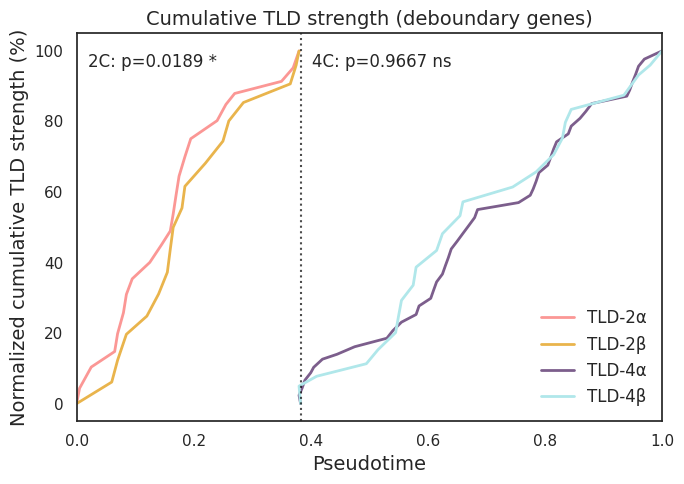


Saved -> IVF_deTAD_SubgroupNormalized_curves.csv


In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
sns.set(style="white")

# ========== 全局参数 ==========
BIN_SIZE = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time_orig = 5.5

# ========== 1. 读取 TAD strength 数据 ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')

# ========== 2. 读取基因列表 ==========
gene_list = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/IVF_morula_boundaries_80k_2C_4C_deboundary2gene_id.txt",
    header=None
)[0].tolist()
gene_set = set(gene_list)
tad_filtered = tad_strength.loc[tad_strength.index.intersection(gene_set)].copy()
print(f"[deTAD] 筛选 deboundary 基因后 TAD 矩阵形状: {tad_filtered.shape}")

# ========== 3. 读取时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

if len(sample_to_time) == 0:
    raise ValueError("时间映射为空，无法继续分析。")

all_times = np.array(list(sample_to_time.values()), dtype=float)
t_min_global = all_times.min()
t_max_global = all_times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time_orig - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 4. 读取亚群 ID ==========
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_2C_C1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_C2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_D1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_D2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# 标签与上文保持一致
subgroups = {
    'TLD-2α': subgroup_2C_C1,
    'TLD-2β': subgroup_2C_C2,
    'TLD-4α': subgroup_4C_D1,
    'TLD-4β': subgroup_4C_D2
}

labels = ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']

# ========== 5. 辅助函数：分箱累积曲线（支持跳过第一个 bin） ==========
def build_binned_curve(times, values, bin_size, skip_first=False):
    if len(times) == 0:
        return np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    x = bin_mean['bin'].values
    v = bin_mean['value'].values

    if skip_first and len(v) > 1:
        x = x[1:]
        v = v[1:]

    if len(v) == 0:
        return np.array([]), np.array([])

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum

# ========== 6. 构建曲线（亚群内独立归一化） ==========
curves = {}

for sg, cells in subgroups.items():
    # 标签已改为 TLD-2α / TLD-2β / TLD-4α / TLD-4β
    if sg.startswith('TLD-2'):
        stage = '2C'
        time_mask = lambda t: t <= min_time_orig
        skip_first = True
    else:
        stage = '4C'
        time_mask = lambda t: t >= min_time_orig
        skip_first = False

    valid_cells = [c for c in cells if c in tad_filtered.columns and c in sample_to_time]
    if not valid_cells:
        print(f"警告: {sg} 没有有效细胞")
        continue

    sub_data = tad_filtered[valid_cells]
    cell_means = sub_data.mean(axis=0)

    times_raw = np.array([float(sample_to_time[c]) for c in valid_cells], dtype=float)
    values = cell_means.values.astype(float)

    idx = np.argsort(times_raw)
    times_raw = times_raw[idx]
    values = values[idx]

    mask = time_mask(times_raw)
    times_raw = times_raw[mask]
    values = values[mask]

    if len(times_raw) == 0:
        print(f"警告: {sg} 在 {stage} 阶段没有有效细胞")
        continue

    t_min_sub = times_raw.min()
    t_max_sub = times_raw.max()

    if t_max_sub == t_min_sub:
        if stage == '2C':
            times_norm = np.full_like(times_raw, 0.0, dtype=float)
        else:
            times_norm = np.full_like(times_raw, 1.0, dtype=float)
    else:
        if stage == '2C':
            times_norm = threshold_norm * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)
        else:
            times_norm = threshold_norm + (1 - threshold_norm) * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)

    x, cum = build_binned_curve(times_norm, values, BIN_SIZE, skip_first=skip_first)
    if len(x) == 0:
        continue

    curves[sg] = (x, cum, stage)

# 检查曲线完整性
for sg in labels:
    if sg not in curves:
        print(f"错误: {sg} 曲线缺失")

# 打印原始曲线范围
print("\n各曲线原始 x 和 y 范围（跳过第一个 bin 后，未插入起点）:")
for sg in labels:
    if sg in curves:
        x, y, stage = curves[sg]
        print(f"  {sg}: stage={stage}, x_min={x.min():.4f}, x_max={x.max():.4f}, "
              f"y_min={y.min():.4f}, y_max={y.max():.4f}, len={len(x)}")
    else:
        print(f"  {sg}: 曲线缺失")

# ========== 7. 统计检验（基于原始数据，不含插入点） ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

p_2c = np.nan
if 'TLD-2α' in curves and 'TLD-2β' in curves:
    x1, y1, _ = curves['TLD-2α']
    x2, y2, _ = curves['TLD-2β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_2c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

p_4c = np.nan
if 'TLD-4α' in curves and 'TLD-4β' in curves:
    x1, y1, _ = curves['TLD-4α']
    x2, y2, _ = curves['TLD-4β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_4c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

print(f"\nTLD-2α vs TLD-2β p = {p_2c}")
print(f"TLD-4α vs TLD-4β p = {p_4c}")

# ========== 8. 绘图（插入起点） ==========
# 配色与上文一致
colors = {
    'TLD-2α': '#fb9795',
    'TLD-2β': '#E9B44C',
    'TLD-4α': '#7c5e8c',
    'TLD-4β': '#b0e7ea'
}

# 全部实线，与上文一致
linestyles = {
    'TLD-2α': '-',
    'TLD-2β': '-',
    'TLD-4α': '-',
    'TLD-4β': '-'
}

fig, ax = plt.subplots(figsize=(7, 5))

for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:  # 4C
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    ax.plot(x_plot, y_plot, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    if np.isnan(p):
        return f"{label}: p=NA (ns)"
    return f"{label}: {format_p_value(p)} {sig_star(p)}"

ax.text(0.02, 0.95, format_p_text("2C", p_2c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)
ax.text(min(threshold_norm + 0.02, 0.98), 0.95, format_p_text("4C", p_4c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative TLD strength (%)', fontsize=14)
ax.set_title('Cumulative TLD strength (deboundary genes)', fontsize=14)
ax.set_xlim(0, 1)
ax.legend(loc='lower right', fontsize=12, frameon=False)

plt.tight_layout()
plt.savefig('IVF_Cumulative_deTAD_SubgroupNormalized.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ========== 保存插入起点后的曲线数据 ==========
curve_records = []
for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    for xi, yi in zip(x_plot, y_plot):
        curve_records.append([sg, xi, yi])

curve_df = pd.DataFrame(curve_records, columns=["subgroup", "bin", "cumulative_percent"])
curve_df.to_csv("IVF_deTAD_SubgroupNormalized_curves.csv", index=False)
print("\nSaved -> IVF_deTAD_SubgroupNormalized_curves.csv")

[TAD] 原始矩阵形状: (32465, 298) (基因 × 细胞)
[ZGA] 筛选后 TAD 矩阵形状: (3110, 298)
[DEPIGs] 筛选后 TAD 矩阵形状: (4006, 298)
全局分割点 (threshold_norm): 0.3826

===== 处理 ZGA =====
ZGA: TLD-2α vs TLD-2β p = 0.00971794702734692
ZGA: TLD-4α vs TLD-4β p = 0.9534403229648377

===== 处理 DEPIGs =====
DEPIGs: TLD-2α vs TLD-2β p = 0.009370330219186944
DEPIGs: TLD-4α vs TLD-4β p = 0.9235828423830389


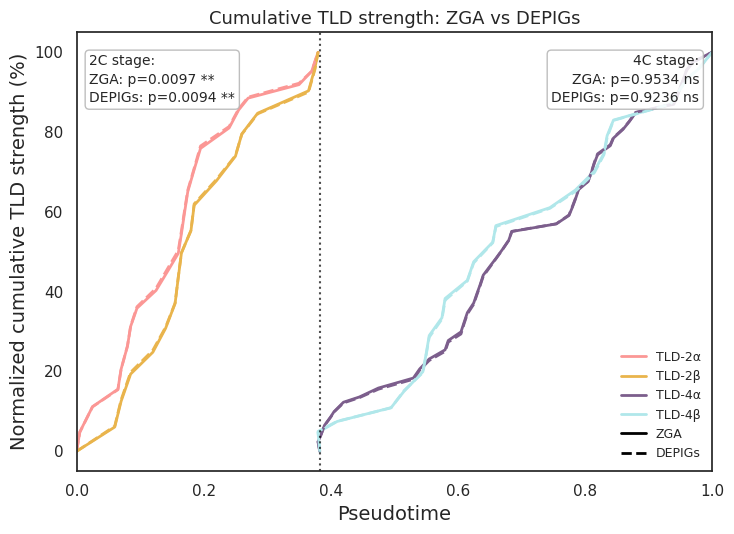


Saved -> IVF_Cumulative_TLD_ZGA_vs_DEPIGs_SubgroupNormalized.csv


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu
from matplotlib.lines import Line2D

# ========== 全局参数 ==========
BIN_SIZE = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time_orig = 5.5

# ========== 1. 读取 TAD strength 数据（只读一次） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')

print(f"[TAD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")

# ========== 2. 基因集：ZGA 与 DEPIGs ==========
gene_files = {
    'ZGA': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_ZGAid.txt",
    'DEPIGs': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_2C_4C_diffEPI_overlap_id.txt"
}

gene_sets = {}
tad_filtered_by_set = {}

for name, path in gene_files.items():
    genes = set(pd.read_csv(path, header=None)[0].tolist())
    gene_sets[name] = genes
    tad_filtered_by_set[name] = tad_strength.loc[tad_strength.index.intersection(genes)].copy()
    print(f"[{name}] 筛选后 TAD 矩阵形状: {tad_filtered_by_set[name].shape}")

# ========== 3. 读取时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

if len(sample_to_time) == 0:
    raise ValueError("时间映射为空，无法继续分析。")

all_times = np.array(list(sample_to_time.values()), dtype=float)
t_min_global = all_times.min()
t_max_global = all_times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time_orig - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 4. 读取亚群 ID ==========
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_2C_C1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_C2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_D1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_D2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

subgroups = {
    'TLD-2α': subgroup_2C_C1,
    'TLD-2β': subgroup_2C_C2,
    'TLD-4α': subgroup_4C_D1,
    'TLD-4β': subgroup_4C_D2
}

labels = ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']

# ========== 5. 辅助函数：分箱累积曲线（支持跳过第一个 bin） ==========
def build_binned_curve(times, values, bin_size, skip_first=False):
    if len(times) == 0:
        return np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    x = bin_mean['bin'].values
    v = bin_mean['value'].values

    if skip_first and len(v) > 1:
        x = x[1:]
        v = v[1:]

    if len(v) == 0:
        return np.array([]), np.array([])

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum

# ========== 6. 对每个基因集构建曲线 ==========
def build_curves_for_gene_set(tad_filtered):
    curves = {}

    for sg, cells in subgroups.items():
        if sg.startswith('TLD-2'):
            stage = '2C'
            time_mask = lambda t: t <= min_time_orig
            skip_first = True
        else:
            stage = '4C'
            time_mask = lambda t: t >= min_time_orig
            skip_first = False

        valid_cells = [c for c in cells if c in tad_filtered.columns and c in sample_to_time]
        if not valid_cells:
            print(f"警告: {sg} 没有有效细胞")
            continue

        sub_data = tad_filtered[valid_cells]
        cell_means = sub_data.mean(axis=0)

        times_raw = np.array([float(sample_to_time[c]) for c in valid_cells], dtype=float)
        values = cell_means.values.astype(float)

        idx = np.argsort(times_raw)
        times_raw = times_raw[idx]
        values = values[idx]

        mask = time_mask(times_raw)
        times_raw = times_raw[mask]
        values = values[mask]

        if len(times_raw) == 0:
            print(f"警告: {sg} 在 {stage} 阶段没有有效细胞")
            continue

        t_min_sub = times_raw.min()
        t_max_sub = times_raw.max()

        if t_max_sub == t_min_sub:
            if stage == '2C':
                times_norm = np.full_like(times_raw, 0.0, dtype=float)
            else:
                times_norm = np.full_like(times_raw, 1.0, dtype=float)
        else:
            if stage == '2C':
                times_norm = threshold_norm * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)
            else:
                times_norm = threshold_norm + (1 - threshold_norm) * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)

        x, cum = build_binned_curve(times_norm, values, BIN_SIZE, skip_first=skip_first)
        if len(x) == 0:
            continue

        curves[sg] = (x, cum, stage)

    return curves

# ========== 7. 统计检验 ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

def calc_p(curves, sg1, sg2):
    p = np.nan
    if sg1 in curves and sg2 in curves:
        x1, y1, _ = curves[sg1]
        x2, y2, _ = curves[sg2]
        _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
        if v1 is not None and len(v1) > 1:
            p = mannwhitneyu(v1, v2, alternative='two-sided').pvalue
    return p

# ========== 8. p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    if np.isnan(p):
        return f"{label}: p=NA (ns)"
    return f"{label}: {format_p_value(p)} {sig_star(p)}"

# ========== 9. 处理两个基因集 ==========
all_curves = {}
p_values = {}

for gene_set in ['ZGA', 'DEPIGs']:
    print(f"\n===== 处理 {gene_set} =====")
    curves = build_curves_for_gene_set(tad_filtered_by_set[gene_set])
    all_curves[gene_set] = curves

    # 检查曲线完整性
    for sg in labels:
        if sg not in curves:
            print(f"错误: {gene_set} {sg} 曲线缺失")

    p_2c = calc_p(curves, 'TLD-2α', 'TLD-2β')
    p_4c = calc_p(curves, 'TLD-4α', 'TLD-4β')
    p_values[gene_set] = {'2C': p_2c, '4C': p_4c}

    print(f"{gene_set}: TLD-2α vs TLD-2β p = {p_2c}")
    print(f"{gene_set}: TLD-4α vs TLD-4β p = {p_4c}")

# ========== 10. 绘图 ==========
fig, ax = plt.subplots(figsize=(7.5, 5.5))

colors = {
    'TLD-2α': '#fb9795',
    'TLD-2β': '#E9B44C',
    'TLD-4α': '#7c5e8c',
    'TLD-4β': '#b0e7ea'
}

linestyles = {
    'ZGA': '-',
    'DEPIGs': '--'
}

for gene_set in ['ZGA', 'DEPIGs']:
    curves = all_curves[gene_set]
    for sg in labels:
        if sg not in curves:
            continue
        x, y, stage = curves[sg]
        if stage == '2C':
            x_plot = np.insert(x, 0, 0.0)
            y_plot = np.insert(y, 0, 0.0)
        else:
            x_plot = np.insert(x, 0, threshold_norm)
            y_plot = np.insert(y, 0, 0.0)
        ax.plot(x_plot, y_plot,
                color=colors[sg], linestyle=linestyles[gene_set],
                linewidth=2)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# p 值文本框：2C 左，4C 右
def build_stage_p_text(stage):
    lines = [f"{stage} stage:"]
    for gene_set in ['ZGA', 'DEPIGs']:
        p = p_values[gene_set][stage]
        if np.isnan(p):
            lines.append(f"{gene_set}: p=NA (ns)")
        else:
            lines.append(f"{gene_set}: {format_p_value(p)} {sig_star(p)}")
    return "\n".join(lines)

ax.text(0.02, 0.95, build_stage_p_text('2C'),
        transform=ax.transAxes, va='top', ha='left', fontsize=10,
        linespacing=1.4,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='0.7'))

ax.text(0.98, 0.95, build_stage_p_text('4C'),
        transform=ax.transAxes, va='top', ha='right', fontsize=10,
        linespacing=1.4,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='0.7'))

# 自定义图例：颜色表示亚群，线型表示基因集
legend_elements = [
    Line2D([0], [0], color=colors['TLD-2α'], lw=2, linestyle='-', label='TLD-2α'),
    Line2D([0], [0], color=colors['TLD-2β'], lw=2, linestyle='-', label='TLD-2β'),
    Line2D([0], [0], color=colors['TLD-4α'], lw=2, linestyle='-', label='TLD-4α'),
    Line2D([0], [0], color=colors['TLD-4β'], lw=2, linestyle='-', label='TLD-4β'),
    Line2D([0], [0], color='black', lw=2, linestyle='-', label='ZGA'),
    Line2D([0], [0], color='black', lw=2, linestyle='--', label='DEPIGs')
]

ax.legend(handles=legend_elements, loc='lower right', fontsize=9, frameon=False)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative TLD strength (%)', fontsize=14)
ax.set_title('Cumulative TLD strength: ZGA vs DEPIGs', fontsize=13)
ax.set_xlim(0, 1)

plt.tight_layout()
plt.savefig('IVF_Cumulative_TLD_ZGA_vs_DEPIGs_SubgroupNormalized.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ========== 11. 保存曲线数据 ==========
curve_records = []
for gene_set in ['ZGA', 'DEPIGs']:
    curves = all_curves[gene_set]
    for sg in labels:
        if sg not in curves:
            continue
        x, y, stage = curves[sg]
        if stage == '2C':
            x_plot = np.insert(x, 0, 0.0)
            y_plot = np.insert(y, 0, 0.0)
        else:
            x_plot = np.insert(x, 0, threshold_norm)
            y_plot = np.insert(y, 0, 0.0)
        for xi, yi in zip(x_plot, y_plot):
            curve_records.append([gene_set, sg, xi, yi])

curve_df = pd.DataFrame(curve_records, columns=["gene_set", "subgroup", "bin", "cumulative_percent"])
curve_df.to_csv("IVF_Cumulative_TLD_ZGA_vs_DEPIGs_SubgroupNormalized.csv", index=False)
print("\nSaved -> IVF_Cumulative_TLD_ZGA_vs_DEPIGs_SubgroupNormalized.csv")

[DEPIGs] 筛选后 TAD 矩阵形状: (4006, 298)
全局分割点 (threshold_norm): 0.3826

各曲线原始 x 和 y 范围（跳过第一个 bin 后，未插入起点）:
  TLD-2α: stage=2C, x_min=0.0050, x_max=0.3800, y_min=4.7728, y_max=100.0000, len=21
  TLD-2β: stage=2C, x_min=0.0600, x_max=0.3800, y_min=6.3034, y_max=100.0000, len=17
  TLD-4α: stage=4C, x_min=0.3800, x_max=1.0000, y_min=2.3933, y_max=100.0000, len=46
  TLD-4β: stage=4C, x_min=0.3800, x_max=1.0000, y_min=4.9885, y_max=100.0000, len=23

TLD-2α vs TLD-2β p = 0.009370330219186944
TLD-4α vs TLD-4β p = 0.9235828423830389


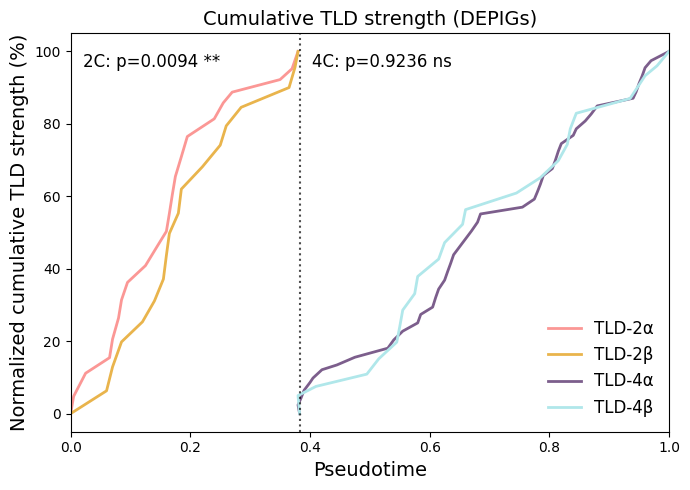


Saved -> IVF_DEPIGs_SubgroupNormalized_curves.csv


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

# ========== 全局参数 ==========
BIN_SIZE = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time_orig = 5.5

# ========== 1. 读取 TAD strength 数据 ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')

# ========== 2. 读取基因列表（DEPIGs） ==========
gene_list = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_2C_4C_diffEPI_overlap_id.txt",
    header=None
)[0].tolist()
gene_set = set(gene_list)
tad_filtered = tad_strength.loc[tad_strength.index.intersection(gene_set)].copy()
print(f"[DEPIGs] 筛选后 TAD 矩阵形状: {tad_filtered.shape}")

# ========== 3. 读取时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

if len(sample_to_time) == 0:
    raise ValueError("时间映射为空，无法继续分析。")

all_times = np.array(list(sample_to_time.values()), dtype=float)
t_min_global = all_times.min()
t_max_global = all_times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time_orig - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 4. 读取亚群 ID ==========
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_2C_C1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_C2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_D1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_D2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# 标签与上文保持一致
subgroups = {
    'TLD-2α': subgroup_2C_C1,
    'TLD-2β': subgroup_2C_C2,
    'TLD-4α': subgroup_4C_D1,
    'TLD-4β': subgroup_4C_D2
}

labels = ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']

# ========== 5. 辅助函数：分箱累积曲线（支持跳过第一个 bin） ==========
def build_binned_curve(times, values, bin_size, skip_first=False):
    if len(times) == 0:
        return np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    x = bin_mean['bin'].values
    v = bin_mean['value'].values

    if skip_first and len(v) > 1:
        x = x[1:]
        v = v[1:]

    if len(v) == 0:
        return np.array([]), np.array([])

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum

# ========== 6. 构建曲线（亚群内独立归一化） ==========
curves = {}

for sg, cells in subgroups.items():
    # 标签已改为 TLD-2α / TLD-2β / TLD-4α / TLD-4β
    if sg.startswith('TLD-2'):
        stage = '2C'
        time_mask = lambda t: t <= min_time_orig
        skip_first = True   # 2C 跳过第一个 bin
    else:
        stage = '4C'
        time_mask = lambda t: t >= min_time_orig
        skip_first = False

    valid_cells = [c for c in cells if c in tad_filtered.columns and c in sample_to_time]
    if not valid_cells:
        print(f"警告: {sg} 没有有效细胞")
        continue

    sub_data = tad_filtered[valid_cells]
    cell_means = sub_data.mean(axis=0)

    times_raw = np.array([float(sample_to_time[c]) for c in valid_cells], dtype=float)
    values = cell_means.values.astype(float)

    idx = np.argsort(times_raw)
    times_raw = times_raw[idx]
    values = values[idx]

    mask = time_mask(times_raw)
    times_raw = times_raw[mask]
    values = values[mask]

    if len(times_raw) == 0:
        print(f"警告: {sg} 在 {stage} 阶段没有有效细胞")
        continue

    t_min_sub = times_raw.min()
    t_max_sub = times_raw.max()

    if t_max_sub == t_min_sub:
        if stage == '2C':
            times_norm = np.full_like(times_raw, 0.0, dtype=float)
        else:
            times_norm = np.full_like(times_raw, 1.0, dtype=float)
    else:
        if stage == '2C':
            times_norm = threshold_norm * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)
        else:
            times_norm = threshold_norm + (1 - threshold_norm) * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)

    x, cum = build_binned_curve(times_norm, values, BIN_SIZE, skip_first=skip_first)
    if len(x) == 0:
        continue

    curves[sg] = (x, cum, stage)

# 检查曲线完整性
for sg in labels:
    if sg not in curves:
        print(f"错误: {sg} 曲线缺失")

# 打印原始曲线范围
print("\n各曲线原始 x 和 y 范围（跳过第一个 bin 后，未插入起点）:")
for sg in labels:
    if sg in curves:
        x, y, stage = curves[sg]
        print(f"  {sg}: stage={stage}, x_min={x.min():.4f}, x_max={x.max():.4f}, "
              f"y_min={y.min():.4f}, y_max={y.max():.4f}, len={len(x)}")
    else:
        print(f"  {sg}: 曲线缺失")

# ========== 7. 统计检验（基于原始数据，不含插入点） ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

p_2c = np.nan
if 'TLD-2α' in curves and 'TLD-2β' in curves:
    x1, y1, _ = curves['TLD-2α']
    x2, y2, _ = curves['TLD-2β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_2c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

p_4c = np.nan
if 'TLD-4α' in curves and 'TLD-4β' in curves:
    x1, y1, _ = curves['TLD-4α']
    x2, y2, _ = curves['TLD-4β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_4c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

print(f"\nTLD-2α vs TLD-2β p = {p_2c}")
print(f"TLD-4α vs TLD-4β p = {p_4c}")

# ========== 8. 绘图（插入起点） ==========
# 配色与上文一致
colors = {
    'TLD-2α': '#fb9795',
    'TLD-2β': '#E9B44C',
    'TLD-4α': '#7c5e8c',
    'TLD-4β': '#b0e7ea'
}

# 全部实线，与上文一致
linestyles = {
    'TLD-2α': '-',
    'TLD-2β': '-',
    'TLD-4α': '-',
    'TLD-4β': '-'
}

fig, ax = plt.subplots(figsize=(7, 5))

for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:  # 4C
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    ax.plot(x_plot, y_plot, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    if np.isnan(p):
        return f"{label}: p=NA (ns)"
    return f"{label}: {format_p_value(p)} {sig_star(p)}"

ax.text(0.02, 0.95, format_p_text("2C", p_2c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)
ax.text(min(threshold_norm + 0.02, 0.98), 0.95, format_p_text("4C", p_4c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative TLD strength (%)', fontsize=14)
ax.set_title('Cumulative TLD strength (DEPIGs)', fontsize=14)
ax.set_xlim(0, 1)
ax.legend(loc='lower right', fontsize=12, frameon=False)

plt.tight_layout()
plt.savefig('IVF_Cumulative_DEPIGs_SubgroupNormalized.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ========== 保存插入起点后的曲线数据 ==========
curve_records = []
for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    for xi, yi in zip(x_plot, y_plot):
        curve_records.append([sg, xi, yi])

curve_df = pd.DataFrame(curve_records, columns=["subgroup", "bin", "cumulative_percent"])
curve_df.to_csv("IVF_DEPIGs_SubgroupNormalized_curves.csv", index=False)
print("\nSaved -> IVF_DEPIGs_SubgroupNormalized_curves.csv")

[ZGA] 筛选后 TAD 矩阵形状: (3110, 298)
全局分割点 (threshold_norm): 0.3826

各曲线原始 x 和 y 范围（跳过第一个 bin 后，未插入起点）:
  TLD-2α: stage=2C, x_min=0.0050, x_max=0.3800, y_min=4.8316, y_max=100.0000, len=21
  TLD-2β: stage=2C, x_min=0.0600, x_max=0.3800, y_min=6.0855, y_max=100.0000, len=17
  TLD-4α: stage=4C, x_min=0.3800, x_max=1.0000, y_min=2.4000, y_max=100.0000, len=46
  TLD-4β: stage=4C, x_min=0.3800, x_max=1.0000, y_min=4.7490, y_max=100.0000, len=23

TLD-2α vs TLD-2β p = 0.00971794702734692
TLD-4α vs TLD-4β p = 0.9534403229648377


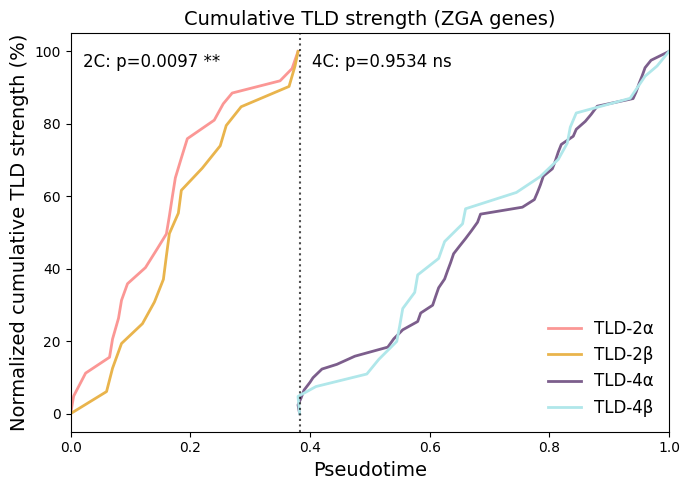


Saved -> IVF_ZGA_SubgroupNormalized_curves.csv


In [17]:
# ZGA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

# ========== 全局参数 ==========
BIN_SIZE = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time_orig = 5.5

# ========== 1. 读取 TAD strength 数据 ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')

# ========== 2. 读取基因列表（ZGA） ==========
gene_list = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_ZGAid.txt",
    header=None
)[0].tolist()
gene_set = set(gene_list)
tad_filtered = tad_strength.loc[tad_strength.index.intersection(gene_set)].copy()
print(f"[ZGA] 筛选后 TAD 矩阵形状: {tad_filtered.shape}")

# ========== 3. 读取时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

if len(sample_to_time) == 0:
    raise ValueError("时间映射为空，无法继续分析。")

all_times = np.array(list(sample_to_time.values()), dtype=float)
t_min_global = all_times.min()
t_max_global = all_times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time_orig - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 4. 读取亚群 ID ==========
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_2C_C1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_C2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_D1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_D2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# 标签与上文保持一致
subgroups = {
    'TLD-2α': subgroup_2C_C1,
    'TLD-2β': subgroup_2C_C2,
    'TLD-4α': subgroup_4C_D1,
    'TLD-4β': subgroup_4C_D2
}

labels = ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']

# ========== 5. 辅助函数：分箱累积曲线（支持跳过第一个 bin） ==========
def build_binned_curve(times, values, bin_size, skip_first=False):
    if len(times) == 0:
        return np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    x = bin_mean['bin'].values
    v = bin_mean['value'].values

    if skip_first and len(v) > 1:
        x = x[1:]
        v = v[1:]

    if len(v) == 0:
        return np.array([]), np.array([])

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum

# ========== 6. 构建曲线（亚群内独立归一化） ==========
curves = {}

for sg, cells in subgroups.items():
    # 标签已改为 TLD-2α / TLD-2β / TLD-4α / TLD-4β
    if sg.startswith('TLD-2'):
        stage = '2C'
        time_mask = lambda t: t <= min_time_orig
        skip_first = True   # 2C 跳过第一个 bin
    else:
        stage = '4C'
        time_mask = lambda t: t >= min_time_orig
        skip_first = False

    valid_cells = [c for c in cells if c in tad_filtered.columns and c in sample_to_time]
    if not valid_cells:
        print(f"警告: {sg} 没有有效细胞")
        continue

    sub_data = tad_filtered[valid_cells]
    cell_means = sub_data.mean(axis=0)

    times_raw = np.array([float(sample_to_time[c]) for c in valid_cells], dtype=float)
    values = cell_means.values.astype(float)

    idx = np.argsort(times_raw)
    times_raw = times_raw[idx]
    values = values[idx]

    mask = time_mask(times_raw)
    times_raw = times_raw[mask]
    values = values[mask]

    if len(times_raw) == 0:
        print(f"警告: {sg} 在 {stage} 阶段没有有效细胞")
        continue

    t_min_sub = times_raw.min()
    t_max_sub = times_raw.max()

    if t_max_sub == t_min_sub:
        if stage == '2C':
            times_norm = np.full_like(times_raw, 0.0, dtype=float)
        else:
            times_norm = np.full_like(times_raw, 1.0, dtype=float)
    else:
        if stage == '2C':
            times_norm = threshold_norm * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)
        else:
            times_norm = threshold_norm + (1 - threshold_norm) * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)

    x, cum = build_binned_curve(times_norm, values, BIN_SIZE, skip_first=skip_first)
    if len(x) == 0:
        continue

    curves[sg] = (x, cum, stage)

# 检查曲线完整性
for sg in labels:
    if sg not in curves:
        print(f"错误: {sg} 曲线缺失")

# 打印原始曲线范围
print("\n各曲线原始 x 和 y 范围（跳过第一个 bin 后，未插入起点）:")
for sg in labels:
    if sg in curves:
        x, y, stage = curves[sg]
        print(f"  {sg}: stage={stage}, x_min={x.min():.4f}, x_max={x.max():.4f}, "
              f"y_min={y.min():.4f}, y_max={y.max():.4f}, len={len(x)}")
    else:
        print(f"  {sg}: 曲线缺失")

# ========== 7. 统计检验（基于原始数据，不含插入点） ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

p_2c = np.nan
if 'TLD-2α' in curves and 'TLD-2β' in curves:
    x1, y1, _ = curves['TLD-2α']
    x2, y2, _ = curves['TLD-2β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_2c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

p_4c = np.nan
if 'TLD-4α' in curves and 'TLD-4β' in curves:
    x1, y1, _ = curves['TLD-4α']
    x2, y2, _ = curves['TLD-4β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_4c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

print(f"\nTLD-2α vs TLD-2β p = {p_2c}")
print(f"TLD-4α vs TLD-4β p = {p_4c}")

# ========== 8. 绘图（插入起点） ==========
# 配色与上文一致
colors = {
    'TLD-2α': '#fb9795',
    'TLD-2β': '#E9B44C',
    'TLD-4α': '#7c5e8c',
    'TLD-4β': '#b0e7ea'
}

# 全部实线，与上文一致
linestyles = {
    'TLD-2α': '-',
    'TLD-2β': '-',
    'TLD-4α': '-',
    'TLD-4β': '-'
}

fig, ax = plt.subplots(figsize=(7, 5))

for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:  # 4C
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    ax.plot(x_plot, y_plot, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    if np.isnan(p):
        return f"{label}: p=NA (ns)"
    return f"{label}: {format_p_value(p)} {sig_star(p)}"

ax.text(0.02, 0.95, format_p_text("2C", p_2c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)
ax.text(min(threshold_norm + 0.02, 0.98), 0.95, format_p_text("4C", p_4c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative TLD strength (%)', fontsize=14)
ax.set_title('Cumulative TLD strength (ZGA genes)', fontsize=14)
ax.set_xlim(0, 1)
ax.legend(loc='lower right', fontsize=12, frameon=False)

plt.tight_layout()
plt.savefig('IVF_Cumulative_ZGA_SubgroupNormalized.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ========== 保存插入起点后的曲线数据 ==========
curve_records = []
for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    for xi, yi in zip(x_plot, y_plot):
        curve_records.append([sg, xi, yi])

curve_df = pd.DataFrame(curve_records, columns=["subgroup", "bin", "cumulative_percent"])
curve_df.to_csv("IVF_ZGA_SubgroupNormalized_curves.csv", index=False)
print("\nSaved -> IVF_ZGA_SubgroupNormalized_curves.csv")

全局分割点 (threshold_norm): 0.3826
APA 数据有效细胞数: 287

===== 每个亚群每个阶段的 bin 统计（跳过第一个 bin 后） =====
TLD-2α (2C): bins=21, cells=34, avg=1.62
TLD-2β (2C): bins=17, cells=22, avg=1.29
TLD-4α (4C): bins=44, cells=121, avg=2.75
TLD-4β (4C): bins=21, cells=56, avg=2.67

TLD-2α vs TLD-2β p = 0.028911381532807725
TLD-4α vs TLD-4β p = 0.7926788525965403


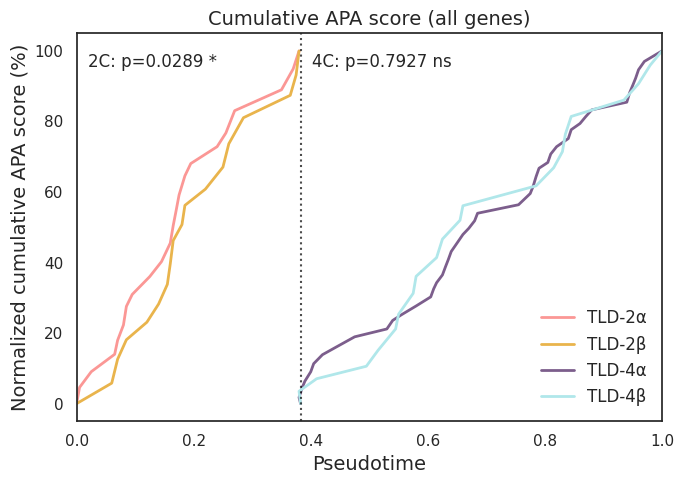


Saved -> IVF_Cumulative_APA_AllGenes_SubgroupNormalized.csv


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
sns.set(style="white")

# ========== 全局参数 ==========
BIN_SIZE = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time_orig = 5.5      # IVF 2C/4C 分界原始时间

# ========== 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

if len(sample_to_time) == 0:
    raise ValueError("时间映射为空，无法继续分析。")

all_times = np.array(list(sample_to_time.values()), dtype=float)
t_min_global = all_times.min()
t_max_global = all_times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time_orig - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 读取四个亚群的细胞 ID ==========
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_2C_C1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_C2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_D1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_D2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# 标签与上文保持一致
subgroups = {
    'TLD-2α': subgroup_2C_C1,
    'TLD-2β': subgroup_2C_C2,
    'TLD-4α': subgroup_4C_D1,
    'TLD-4β': subgroup_4C_D2
}

labels = ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']

# ========== 读取新的 APA z-score 数据（所有基因，无 type 列） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/loop_apa_0.925/single_cell/all_genes_loopAPA/allgenes_APA_zscore_summary.txt",
    sep="\t"
)
# 确保列名正确
apa_df.columns = ['cell', 'z_score']   # 文件只有两列
# 按细胞平均（如果有多行，但目前看起来每个细胞一行）
cell_avg = apa_df[['cell', 'z_score']].rename(columns={'z_score': 'value'})
cell_avg['value'] = pd.to_numeric(cell_avg['value'], errors='coerce')
cell_avg = cell_avg.dropna(subset=['value'])

# 只保留在 sample_to_time 中的细胞
cell_avg = cell_avg[cell_avg['cell'].isin(sample_to_time)]
print(f"APA 数据有效细胞数: {len(cell_avg)}")

# ========== 辅助函数：分箱累积曲线（支持跳过第一个 bin） ==========
def build_binned_curve(times, values, bin_size, skip_first=False):
    if len(times) == 0:
        return np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    x = bin_mean['bin'].values
    v = bin_mean['value'].values

    if skip_first and len(v) > 1:
        x = x[1:]
        v = v[1:]

    if len(v) == 0:
        return np.array([]), np.array([])

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum

# ========== 构建曲线（亚群内独立归一化） ==========
curves = {}                # 存储 (x, cum, stage)
bin_stats = {}             # 存储每个亚群每个阶段的 bin 数量、细胞数等

for sg, cells in subgroups.items():
    # 标签已改为 TLD-2α / TLD-2β / TLD-4α / TLD-4β
    if sg.startswith('TLD-2'):
        stage = '2C'
        time_mask = lambda t: t <= min_time_orig
        skip_first = True
    else:
        stage = '4C'
        time_mask = lambda t: t >= min_time_orig
        skip_first = False

    # 筛选存在于 APA 数据中的细胞
    valid_cells = [c for c in cells if c in cell_avg['cell'].values and c in sample_to_time]
    if not valid_cells:
        print(f"警告: {sg} 没有有效 APA 细胞")
        continue

    # 提取该亚群的数据
    sub = cell_avg[cell_avg['cell'].isin(valid_cells)].copy()
    # 添加原始时间
    sub['time_raw'] = sub['cell'].map(sample_to_time)
    sub = sub.dropna(subset=['time_raw'])

    # 按阶段筛选
    mask = time_mask(sub['time_raw'].values)
    sub = sub[mask]
    if sub.empty:
        print(f"警告: {sg} 在 {stage} 阶段没有细胞")
        continue

    # 按时间排序
    sub = sub.sort_values('time_raw')
    times_raw = sub['time_raw'].values.astype(float)
    values = sub['value'].values.astype(float)

    # 亚群内独立归一化
    t_min_sub = times_raw.min()
    t_max_sub = times_raw.max()

    if t_max_sub == t_min_sub:
        if stage == '2C':
            times_norm = np.full_like(times_raw, 0.0, dtype=float)
        else:
            times_norm = np.full_like(times_raw, 1.0, dtype=float)
    else:
        if stage == '2C':
            times_norm = threshold_norm * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)
        else:
            times_norm = threshold_norm + (1 - threshold_norm) * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)

    # 分箱累积曲线
    x, cum = build_binned_curve(times_norm, values, BIN_SIZE, skip_first=skip_first)
    if len(x) == 0:
        print(f"警告: {sg} 累积曲线为空")
        continue

    # 记录 bin 统计信息（原始分箱，未插入起点）
    bin_counts = pd.DataFrame({'time': times_norm, 'value': values})
    bin_counts['bin'] = np.floor(bin_counts['time'] / BIN_SIZE) * BIN_SIZE

    if skip_first:
        bins_keep = np.unique(bin_counts['bin'])[1:] if len(np.unique(bin_counts['bin'])) > 1 else []
        bin_counts = bin_counts[bin_counts['bin'].isin(bins_keep)]

    n_bins = len(np.unique(bin_counts['bin']))
    n_cells = len(bin_counts)
    avg_cells_per_bin = n_cells / n_bins if n_bins > 0 else 0

    bin_stats[sg] = {
        'stage': stage,
        'n_bins': n_bins,
        'n_cells': n_cells,
        'avg_cells_per_bin': avg_cells_per_bin
    }

    curves[sg] = (x, cum, stage)

# 打印每个亚群的 bin 统计
print("\n===== 每个亚群每个阶段的 bin 统计（跳过第一个 bin 后） =====")
for sg in labels:
    if sg in bin_stats:
        stats = bin_stats[sg]
        print(f"{sg} ({stats['stage']}): bins={stats['n_bins']}, cells={stats['n_cells']}, "
              f"avg={stats['avg_cells_per_bin']:.2f}")
    else:
        print(f"{sg}: 无数据")

# 检查曲线完整性
for sg in labels:
    if sg not in curves:
        print(f"错误: {sg} 曲线缺失")

# ========== 统计检验（基于原始数据，不含插入点） ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

p_2c = np.nan
if 'TLD-2α' in curves and 'TLD-2β' in curves:
    x1, y1, _ = curves['TLD-2α']
    x2, y2, _ = curves['TLD-2β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_2c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

p_4c = np.nan
if 'TLD-4α' in curves and 'TLD-4β' in curves:
    x1, y1, _ = curves['TLD-4α']
    x2, y2, _ = curves['TLD-4β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_4c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

print(f"\nTLD-2α vs TLD-2β p = {p_2c}")
print(f"TLD-4α vs TLD-4β p = {p_4c}")

# ========== 绘图（插入起点） ==========
# 配色与上文一致
colors = {
    'TLD-2α': '#fb9795',
    'TLD-2β': '#E9B44C',
    'TLD-4α': '#7c5e8c',
    'TLD-4β': '#b0e7ea'
}

# 全部实线，与上文一致
linestyles = {
    'TLD-2α': '-',
    'TLD-2β': '-',
    'TLD-4α': '-',
    'TLD-4β': '-'
}

fig, ax = plt.subplots(figsize=(7, 5))

for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:  # 4C
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    ax.plot(x_plot, y_plot, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    if np.isnan(p):
        return f"{label}: p=NA (ns)"
    return f"{label}: {format_p_value(p)} {sig_star(p)}"

ax.text(0.02, 0.95, format_p_text("2C", p_2c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)
ax.text(min(threshold_norm + 0.02, 0.98), 0.95, format_p_text("4C", p_4c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative APA score (%)', fontsize=14)
ax.set_title('Cumulative APA score (all genes)', fontsize=14)
ax.set_xlim(0, 1)
ax.legend(loc='lower right', fontsize=12, frameon=False)

plt.tight_layout()
plt.savefig('IVF_Cumulative_APA_AllGenes_SubgroupNormalized.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ========== 保存曲线数据 ==========
curve_records = []
for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    for xi, yi in zip(x_plot, y_plot):
        curve_records.append([sg, xi, yi])

curve_df = pd.DataFrame(curve_records, columns=["subgroup", "bin", "cumulative_percent"])
curve_df.to_csv("IVF_Cumulative_APA_AllGenes_SubgroupNormalized.csv", index=False)
print("\nSaved -> IVF_Cumulative_APA_AllGenes_SubgroupNormalized.csv")

全局分割点 (threshold_norm): 0.3826
APA 数据有效细胞数: 287

===== 每个亚群每个阶段的 bin 统计（跳过第一个 bin 后） =====
TLD-2α (2C): bins=21, cells=34, avg=1.62
TLD-2β (2C): bins=17, cells=22, avg=1.29
TLD-4α (4C): bins=44, cells=121, avg=2.75
TLD-4β (4C): bins=21, cells=56, avg=2.67

TLD-2α vs TLD-2β p = 0.022810608233276984
TLD-4α vs TLD-4β p = 0.316695916212295


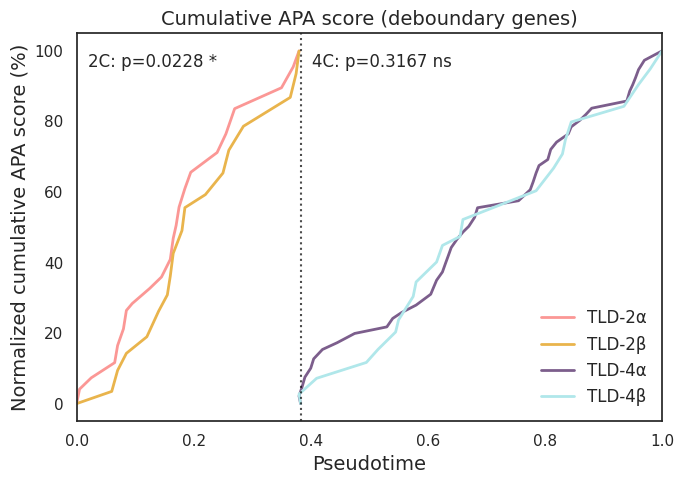


Saved -> IVF_Cumulative_APA_deBoundary_Genes_SubgroupNormalized.csv


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
sns.set(style="white")

# ========== 全局参数 ==========
BIN_SIZE = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time_orig = 5.5      # IVF 2C/4C 分界原始时间

# ========== 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

if len(sample_to_time) == 0:
    raise ValueError("时间映射为空，无法继续分析。")

all_times = np.array(list(sample_to_time.values()), dtype=float)
t_min_global = all_times.min()
t_max_global = all_times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time_orig - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 读取四个亚群的细胞 ID ==========
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_2C_C1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_C2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_D1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_D2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# 标签与上文保持一致
subgroups = {
    'TLD-2α': subgroup_2C_C1,
    'TLD-2β': subgroup_2C_C2,
    'TLD-4α': subgroup_4C_D1,
    'TLD-4β': subgroup_4C_D2
}

labels = ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']

# ========== 读取新的 APA z-score 数据（deboundary 基因，无 type 列） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/loop_apa_0.925/single_cell/IVF_deboundary_APA_zscore_summary.txt",
    sep="\t"
)
# 确保列名正确
apa_df.columns = ['cell', 'z_score']   # 文件只有两列
# 按细胞平均（如果有多行，但目前看起来每个细胞一行）
cell_avg = apa_df[['cell', 'z_score']].rename(columns={'z_score': 'value'})
cell_avg['value'] = pd.to_numeric(cell_avg['value'], errors='coerce')
cell_avg = cell_avg.dropna(subset=['value'])

# 只保留在 sample_to_time 中的细胞
cell_avg = cell_avg[cell_avg['cell'].isin(sample_to_time)]
print(f"APA 数据有效细胞数: {len(cell_avg)}")

# ========== 辅助函数：分箱累积曲线（支持跳过第一个 bin） ==========
def build_binned_curve(times, values, bin_size, skip_first=False):
    if len(times) == 0:
        return np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    x = bin_mean['bin'].values
    v = bin_mean['value'].values

    if skip_first and len(v) > 1:
        x = x[1:]
        v = v[1:]

    if len(v) == 0:
        return np.array([]), np.array([])

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum

# ========== 构建曲线（亚群内独立归一化） ==========
curves = {}                # 存储 (x, cum, stage)
bin_stats = {}             # 存储每个亚群每个阶段的 bin 数量、细胞数等

for sg, cells in subgroups.items():
    # 标签已改为 TLD-2α / TLD-2β / TLD-4α / TLD-4β
    if sg.startswith('TLD-2'):
        stage = '2C'
        time_mask = lambda t: t <= min_time_orig
        skip_first = True
    else:
        stage = '4C'
        time_mask = lambda t: t >= min_time_orig
        skip_first = False

    # 筛选存在于 APA 数据中的细胞
    valid_cells = [c for c in cells if c in cell_avg['cell'].values and c in sample_to_time]
    if not valid_cells:
        print(f"警告: {sg} 没有有效 APA 细胞")
        continue

    # 提取该亚群的数据
    sub = cell_avg[cell_avg['cell'].isin(valid_cells)].copy()
    # 添加原始时间
    sub['time_raw'] = sub['cell'].map(sample_to_time)
    sub = sub.dropna(subset=['time_raw'])

    # 按阶段筛选
    mask = time_mask(sub['time_raw'].values)
    sub = sub[mask]
    if sub.empty:
        print(f"警告: {sg} 在 {stage} 阶段没有细胞")
        continue

    # 按时间排序
    sub = sub.sort_values('time_raw')
    times_raw = sub['time_raw'].values.astype(float)
    values = sub['value'].values.astype(float)

    # 亚群内独立归一化
    t_min_sub = times_raw.min()
    t_max_sub = times_raw.max()

    if t_max_sub == t_min_sub:
        if stage == '2C':
            times_norm = np.full_like(times_raw, 0.0, dtype=float)
        else:
            times_norm = np.full_like(times_raw, 1.0, dtype=float)
    else:
        if stage == '2C':
            times_norm = threshold_norm * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)
        else:
            times_norm = threshold_norm + (1 - threshold_norm) * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)

    # 分箱累积曲线
    x, cum = build_binned_curve(times_norm, values, BIN_SIZE, skip_first=skip_first)
    if len(x) == 0:
        print(f"警告: {sg} 累积曲线为空")
        continue

    # 记录 bin 统计信息（原始分箱，未插入起点）
    bin_counts = pd.DataFrame({'time': times_norm, 'value': values})
    bin_counts['bin'] = np.floor(bin_counts['time'] / BIN_SIZE) * BIN_SIZE

    if skip_first:
        bins_keep = np.unique(bin_counts['bin'])[1:] if len(np.unique(bin_counts['bin'])) > 1 else []
        bin_counts = bin_counts[bin_counts['bin'].isin(bins_keep)]

    n_bins = len(np.unique(bin_counts['bin']))
    n_cells = len(bin_counts)
    avg_cells_per_bin = n_cells / n_bins if n_bins > 0 else 0

    bin_stats[sg] = {
        'stage': stage,
        'n_bins': n_bins,
        'n_cells': n_cells,
        'avg_cells_per_bin': avg_cells_per_bin
    }

    curves[sg] = (x, cum, stage)

# 打印每个亚群的 bin 统计
print("\n===== 每个亚群每个阶段的 bin 统计（跳过第一个 bin 后） =====")
for sg in labels:
    if sg in bin_stats:
        stats = bin_stats[sg]
        print(f"{sg} ({stats['stage']}): bins={stats['n_bins']}, cells={stats['n_cells']}, "
              f"avg={stats['avg_cells_per_bin']:.2f}")
    else:
        print(f"{sg}: 无数据")

# 检查曲线完整性
for sg in labels:
    if sg not in curves:
        print(f"错误: {sg} 曲线缺失")

# ========== 统计检验（基于原始数据，不含插入点） ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

p_2c = np.nan
if 'TLD-2α' in curves and 'TLD-2β' in curves:
    x1, y1, _ = curves['TLD-2α']
    x2, y2, _ = curves['TLD-2β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_2c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

p_4c = np.nan
if 'TLD-4α' in curves and 'TLD-4β' in curves:
    x1, y1, _ = curves['TLD-4α']
    x2, y2, _ = curves['TLD-4β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_4c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

print(f"\nTLD-2α vs TLD-2β p = {p_2c}")
print(f"TLD-4α vs TLD-4β p = {p_4c}")

# ========== 绘图（插入起点） ==========
# 配色与上文一致
colors = {
    'TLD-2α': '#fb9795',
    'TLD-2β': '#E9B44C',
    'TLD-4α': '#7c5e8c',
    'TLD-4β': '#b0e7ea'
}

# 全部实线，与上文一致
linestyles = {
    'TLD-2α': '-',
    'TLD-2β': '-',
    'TLD-4α': '-',
    'TLD-4β': '-'
}

fig, ax = plt.subplots(figsize=(7, 5))

for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:  # 4C
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    ax.plot(x_plot, y_plot, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    if np.isnan(p):
        return f"{label}: p=NA (ns)"
    return f"{label}: {format_p_value(p)} {sig_star(p)}"

ax.text(0.02, 0.95, format_p_text("2C", p_2c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)
ax.text(min(threshold_norm + 0.02, 0.98), 0.95, format_p_text("4C", p_4c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative APA score (%)', fontsize=14)
ax.set_title('Cumulative APA score (deboundary genes)', fontsize=14)
ax.set_xlim(0, 1)
ax.legend(loc='lower right', fontsize=12, frameon=False)

plt.tight_layout()
plt.savefig('IVF_Cumulative_APA_deBoundary_Genes_SubgroupNormalized.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ========== 保存曲线数据 ==========
curve_records = []
for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    for xi, yi in zip(x_plot, y_plot):
        curve_records.append([sg, xi, yi])

curve_df = pd.DataFrame(curve_records, columns=["subgroup", "bin", "cumulative_percent"])
curve_df.to_csv("IVF_Cumulative_APA_deBoundary_Genes_SubgroupNormalized.csv", index=False)
print("\nSaved -> IVF_Cumulative_APA_deBoundary_Genes_SubgroupNormalized.csv")

全局分割点 (threshold_norm): 0.3826

===== 处理 ZGA =====
[ZGA] APA 数据有效细胞数: 287

ZGA bin 统计:
  TLD-2α (2C): bins=21, cells=34, avg=1.62
  TLD-2β (2C): bins=17, cells=22, avg=1.29
  TLD-4α (4C): bins=44, cells=121, avg=2.75
  TLD-4β (4C): bins=21, cells=56, avg=2.67
ZGA: 2C p = 0.022810608233276984, 4C p = 0.316695916212295

===== 处理 DEPIGs =====
[DEPIGs] APA 数据有效细胞数: 287

DEPIGs bin 统计:
  TLD-2α (2C): bins=21, cells=34, avg=1.62
  TLD-2β (2C): bins=17, cells=22, avg=1.29
  TLD-4α (4C): bins=44, cells=121, avg=2.75
  TLD-4β (4C): bins=21, cells=56, avg=2.67
DEPIGs: 2C p = 0.034542624898642925, 4C p = 0.7291376999005268


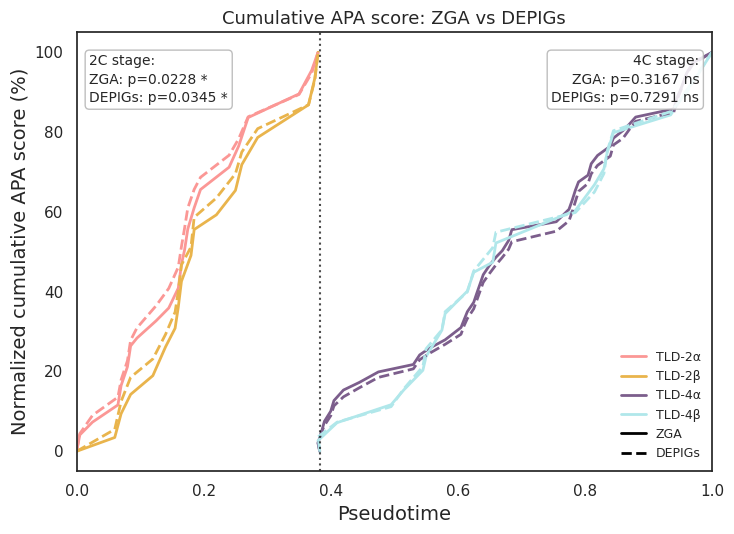


Saved -> IVF_Cumulative_APA_ZGA_vs_DEPIGs_SubgroupNormalized.csv


In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu
from matplotlib.lines import Line2D

# ========== 全局参数 ==========
BIN_SIZE = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time_orig = 5.5      # IVF 2C/4C 分界原始时间

# ========== 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

if len(sample_to_time) == 0:
    raise ValueError("时间映射为空，无法继续分析。")

all_times = np.array(list(sample_to_time.values()), dtype=float)
t_min_global = all_times.min()
t_max_global = all_times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time_orig - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 读取四个亚群的细胞 ID ==========
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_2C_C1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_C2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_D1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_D2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

subgroups = {
    'TLD-2α': subgroup_2C_C1,
    'TLD-2β': subgroup_2C_C2,
    'TLD-4α': subgroup_4C_D1,
    'TLD-4β': subgroup_4C_D2
}

labels = ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']

# ========== APA 文件：ZGA 与 DEPIGs ==========
apa_files = {
    'ZGA': "/home/lihaoxing/jupyter/IVF_ZGA_APA_zscore_summary.txt",
    'DEPIGs': "/home/lihaoxing/jupyter/IVF_diffEPI_APA_zscore_summary.txt"
}

# ========== 辅助函数：分箱累积曲线（支持跳过第一个 bin） ==========
def build_binned_curve(times, values, bin_size, skip_first=False):
    if len(times) == 0:
        return np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    x = bin_mean['bin'].values
    v = bin_mean['value'].values

    if skip_first and len(v) > 1:
        x = x[1:]
        v = v[1:]

    if len(v) == 0:
        return np.array([]), np.array([])

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum

# ========== 读取 APA 文件并构建曲线 ==========
def load_apa(path, gene_set_name):
    apa_df = pd.read_csv(path, sep="\t")
    apa_df = apa_df.iloc[:, :2]
    apa_df.columns = ['cell', 'z_score']
    apa_df['cell'] = (
        apa_df['cell'].astype(str).str.strip()
        .str.replace('"', '').str.replace("'", "")
    )
    apa_df['z_score'] = pd.to_numeric(apa_df['z_score'], errors='coerce')
    apa_df = apa_df.dropna(subset=['z_score'])
    apa_df = apa_df[apa_df['cell'].isin(sample_to_time)]

    print(f"[{gene_set_name}] APA 数据有效细胞数: {len(apa_df)}")
    return apa_df.rename(columns={'z_score': 'value'})


def build_curves_for_gene_set(cell_avg):
    curves = {}       # sg -> (x, cum, stage)
    bin_stats = {}

    for sg, cells in subgroups.items():
        if sg.startswith('TLD-2'):
            stage = '2C'
            time_mask = lambda t: t <= min_time_orig
            skip_first = True
        else:
            stage = '4C'
            time_mask = lambda t: t >= min_time_orig
            skip_first = False

        valid_cells = [c for c in cells if c in cell_avg['cell'].values and c in sample_to_time]
        if not valid_cells:
            print(f"警告: {sg} 没有有效 APA 细胞")
            continue

        sub = cell_avg[cell_avg['cell'].isin(valid_cells)].copy()
        sub['time_raw'] = sub['cell'].map(sample_to_time)
        sub = sub.dropna(subset=['time_raw'])

        mask = time_mask(sub['time_raw'].values)
        sub = sub[mask]

        if sub.empty:
            print(f"警告: {sg} 在 {stage} 阶段没有细胞")
            continue

        sub = sub.sort_values('time_raw')
        times_raw = sub['time_raw'].values.astype(float)
        values = sub['value'].values.astype(float)

        t_min_sub = times_raw.min()
        t_max_sub = times_raw.max()

        if t_max_sub == t_min_sub:
            if stage == '2C':
                times_norm = np.full_like(times_raw, 0.0, dtype=float)
            else:
                times_norm = np.full_like(times_raw, 1.0, dtype=float)
        else:
            if stage == '2C':
                times_norm = threshold_norm * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)
            else:
                times_norm = threshold_norm + (1 - threshold_norm) * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)

        x, cum = build_binned_curve(times_norm, values, BIN_SIZE, skip_first=skip_first)
        if len(x) == 0:
            print(f"警告: {sg} 累积曲线为空")
            continue

        bin_counts = pd.DataFrame({'time': times_norm, 'value': values})
        bin_counts['bin'] = np.floor(bin_counts['time'] / BIN_SIZE) * BIN_SIZE

        if skip_first:
            bins_keep = np.unique(bin_counts['bin'])[1:] if len(np.unique(bin_counts['bin'])) > 1 else []
            bin_counts = bin_counts[bin_counts['bin'].isin(bins_keep)]

        n_bins = len(np.unique(bin_counts['bin']))
        n_cells = len(bin_counts)
        bin_stats[sg] = {
            'stage': stage,
            'n_bins': n_bins,
            'n_cells': n_cells,
            'avg_cells_per_bin': n_cells / n_bins if n_bins > 0 else 0
        }

        curves[sg] = (x, cum, stage)

    return curves, bin_stats


# ========== 统计检验 ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub


def calc_p(curves, sg1, sg2):
    p = np.nan
    if sg1 in curves and sg2 in curves:
        x1, y1, _ = curves[sg1]
        x2, y2, _ = curves[sg2]
        _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
        if v1 is not None and len(v1) > 1:
            p = mannwhitneyu(v1, v2, alternative='two-sided').pvalue
    return p


# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    if np.isnan(p):
        return f"{label}: p=NA (ns)"
    return f"{label}: {format_p_value(p)} {sig_star(p)}"


# ========== 处理两个基因集 ==========
all_curves = {}      # gene_set -> curves dict
p_values = {}        # gene_set -> {'2C': p, '4C': p}

for gene_set, path in apa_files.items():
    print(f"\n===== 处理 {gene_set} =====")
    cell_avg = load_apa(path, gene_set)
    curves, bin_stats = build_curves_for_gene_set(cell_avg)
    all_curves[gene_set] = curves

    print(f"\n{gene_set} bin 统计:")
    for sg in labels:
        if sg in bin_stats:
            s = bin_stats[sg]
            print(f"  {sg} ({s['stage']}): bins={s['n_bins']}, "
                  f"cells={s['n_cells']}, avg={s['avg_cells_per_bin']:.2f}")
        else:
            print(f"  {sg}: 无数据")

    p_2c = calc_p(curves, 'TLD-2α', 'TLD-2β')
    p_4c = calc_p(curves, 'TLD-4α', 'TLD-4β')
    p_values[gene_set] = {'2C': p_2c, '4C': p_4c}

    print(f"{gene_set}: 2C p = {p_2c}, 4C p = {p_4c}")


# ========== 绘图 ==========
fig, ax = plt.subplots(figsize=(7.5, 5.5))

colors = {
    'TLD-2α': '#fb9795',
    'TLD-2β': '#E9B44C',
    'TLD-4α': '#7c5e8c',
    'TLD-4β': '#b0e7ea'
}

linestyles = {
    'ZGA': '-',
    'DEPIGs': '--'
}

for gene_set in ['ZGA', 'DEPIGs']:
    curves = all_curves[gene_set]
    for sg in labels:
        if sg not in curves:
            continue
        x, y, stage = curves[sg]
        if stage == '2C':
            x_plot = np.insert(x, 0, 0.0)
            y_plot = np.insert(y, 0, 0.0)
        else:
            x_plot = np.insert(x, 0, threshold_norm)
            y_plot = np.insert(y, 0, 0.0)
        ax.plot(x_plot, y_plot,
                color=colors[sg], linestyle=linestyles[gene_set],
                linewidth=2)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# p 值文本框：2C 左，4C 右
def build_stage_p_text(stage):
    lines = [f"{stage} stage:"]
    for gene_set in ['ZGA', 'DEPIGs']:
        p = p_values[gene_set][stage]
        if np.isnan(p):
            lines.append(f"{gene_set}: p=NA (ns)")
        else:
            lines.append(f"{gene_set}: {format_p_value(p)} {sig_star(p)}")
    return "\n".join(lines)

ax.text(0.02, 0.95, build_stage_p_text('2C'),
        transform=ax.transAxes, va='top', ha='left', fontsize=10,
        linespacing=1.4,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='0.7'))

ax.text(0.98, 0.95, build_stage_p_text('4C'),
        transform=ax.transAxes, va='top', ha='right', fontsize=10,
        linespacing=1.4,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='0.7'))

# 自定义图例：颜色表示亚群，线型表示基因集
legend_elements = [
    Line2D([0], [0], color=colors['TLD-2α'], lw=2, linestyle='-', label='TLD-2α'),
    Line2D([0], [0], color=colors['TLD-2β'], lw=2, linestyle='-', label='TLD-2β'),
    Line2D([0], [0], color=colors['TLD-4α'], lw=2, linestyle='-', label='TLD-4α'),
    Line2D([0], [0], color=colors['TLD-4β'], lw=2, linestyle='-', label='TLD-4β'),
    Line2D([0], [0], color='black', lw=2, linestyle='-', label='ZGA'),
    Line2D([0], [0], color='black', lw=2, linestyle='--', label='DEPIGs')
]

ax.legend(handles=legend_elements, loc='lower right', fontsize=9, frameon=False)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative APA score (%)', fontsize=14)
ax.set_title('Cumulative APA score: ZGA vs DEPIGs', fontsize=13)
ax.set_xlim(0, 1)

plt.tight_layout()
plt.savefig('IVF_Cumulative_APA_ZGA_vs_DEPIGs_SubgroupNormalized.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()


# ========== 保存曲线数据 ==========
curve_records = []
for gene_set in ['ZGA', 'DEPIGs']:
    curves = all_curves[gene_set]
    for sg in labels:
        if sg not in curves:
            continue
        x, y, stage = curves[sg]
        if stage == '2C':
            x_plot = np.insert(x, 0, 0.0)
            y_plot = np.insert(y, 0, 0.0)
        else:
            x_plot = np.insert(x, 0, threshold_norm)
            y_plot = np.insert(y, 0, 0.0)
        for xi, yi in zip(x_plot, y_plot):
            curve_records.append([gene_set, sg, xi, yi])

curve_df = pd.DataFrame(curve_records, columns=["gene_set", "subgroup", "bin", "cumulative_percent"])
curve_df.to_csv("IVF_Cumulative_APA_ZGA_vs_DEPIGs_SubgroupNormalized.csv", index=False)
print("\nSaved -> IVF_Cumulative_APA_ZGA_vs_DEPIGs_SubgroupNormalized.csv")

全局分割点 (threshold_norm): 0.3826
APA 数据有效细胞数: 287

===== 每个亚群每个阶段的 bin 统计（跳过第一个 bin 后） =====
TLD-2α (2C): bins=21, cells=34, avg=1.62
TLD-2β (2C): bins=17, cells=22, avg=1.29
TLD-4α (4C): bins=44, cells=121, avg=2.75
TLD-4β (4C): bins=21, cells=56, avg=2.67

TLD-2α vs TLD-2β p = 0.034542624898642925
TLD-4α vs TLD-4β p = 0.7291376999005268


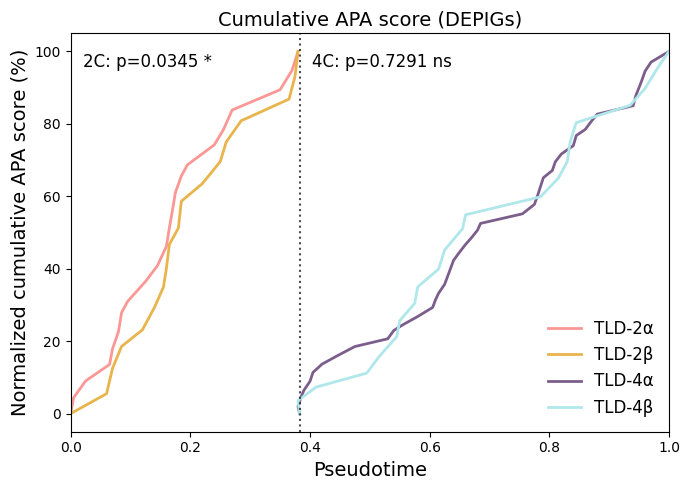


Saved -> IVF_Cumulative_APA_DEPIGs_SubgroupNormalized.csv


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

# ========== 全局参数 ==========
BIN_SIZE = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time_orig = 5.5      # IVF 2C/4C 分界原始时间

# ========== 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

if len(sample_to_time) == 0:
    raise ValueError("时间映射为空，无法继续分析。")

all_times = np.array(list(sample_to_time.values()), dtype=float)
t_min_global = all_times.min()
t_max_global = all_times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time_orig - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 读取四个亚群的细胞 ID ==========
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_2C_C1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_C2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_D1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_D2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# 标签与上文保持一致
subgroups = {
    'TLD-2α': subgroup_2C_C1,
    'TLD-2β': subgroup_2C_C2,
    'TLD-4α': subgroup_4C_D1,
    'TLD-4β': subgroup_4C_D2
}

labels = ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']

# ========== 读取新的 APA z-score 数据（DEPIGs，无 type 列） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/IVF_diffEPI_APA_zscore_summary.txt",
    sep="\t"
)
# 确保列名正确
apa_df.columns = ['cell', 'z_score']   # 文件只有两列
# 按细胞平均（如果有多行，但目前看起来每个细胞一行）
cell_avg = apa_df[['cell', 'z_score']].rename(columns={'z_score': 'value'})
cell_avg['value'] = pd.to_numeric(cell_avg['value'], errors='coerce')
cell_avg = cell_avg.dropna(subset=['value'])

# 只保留在 sample_to_time 中的细胞
cell_avg = cell_avg[cell_avg['cell'].isin(sample_to_time)]
print(f"APA 数据有效细胞数: {len(cell_avg)}")

# ========== 辅助函数：分箱累积曲线（支持跳过第一个 bin） ==========
def build_binned_curve(times, values, bin_size, skip_first=False):
    if len(times) == 0:
        return np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    x = bin_mean['bin'].values
    v = bin_mean['value'].values

    if skip_first and len(v) > 1:
        x = x[1:]
        v = v[1:]

    if len(v) == 0:
        return np.array([]), np.array([])

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum

# ========== 构建曲线（亚群内独立归一化） ==========
curves = {}                # 存储 (x, cum, stage)
bin_stats = {}             # 存储每个亚群每个阶段的 bin 数量、细胞数等

for sg, cells in subgroups.items():
    # 标签已改为 TLD-2α / TLD-2β / TLD-4α / TLD-4β
    if sg.startswith('TLD-2'):
        stage = '2C'
        time_mask = lambda t: t <= min_time_orig
        skip_first = True
    else:
        stage = '4C'
        time_mask = lambda t: t >= min_time_orig
        skip_first = False

    # 筛选存在于 APA 数据中的细胞
    valid_cells = [c for c in cells if c in cell_avg['cell'].values and c in sample_to_time]
    if not valid_cells:
        print(f"警告: {sg} 没有有效 APA 细胞")
        continue

    # 提取该亚群的数据
    sub = cell_avg[cell_avg['cell'].isin(valid_cells)].copy()
    # 添加原始时间
    sub['time_raw'] = sub['cell'].map(sample_to_time)
    sub = sub.dropna(subset=['time_raw'])

    # 按阶段筛选
    mask = time_mask(sub['time_raw'].values)
    sub = sub[mask]
    if sub.empty:
        print(f"警告: {sg} 在 {stage} 阶段没有细胞")
        continue

    # 按时间排序
    sub = sub.sort_values('time_raw')
    times_raw = sub['time_raw'].values.astype(float)
    values = sub['value'].values.astype(float)

    # 亚群内独立归一化
    t_min_sub = times_raw.min()
    t_max_sub = times_raw.max()

    if t_max_sub == t_min_sub:
        if stage == '2C':
            times_norm = np.full_like(times_raw, 0.0, dtype=float)
        else:
            times_norm = np.full_like(times_raw, 1.0, dtype=float)
    else:
        if stage == '2C':
            times_norm = threshold_norm * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)
        else:
            times_norm = threshold_norm + (1 - threshold_norm) * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)

    # 分箱累积曲线
    x, cum = build_binned_curve(times_norm, values, BIN_SIZE, skip_first=skip_first)
    if len(x) == 0:
        print(f"警告: {sg} 累积曲线为空")
        continue

    # 记录 bin 统计信息（原始分箱，未插入起点）
    bin_counts = pd.DataFrame({'time': times_norm, 'value': values})
    bin_counts['bin'] = np.floor(bin_counts['time'] / BIN_SIZE) * BIN_SIZE

    if skip_first:
        bins_keep = np.unique(bin_counts['bin'])[1:] if len(np.unique(bin_counts['bin'])) > 1 else []
        bin_counts = bin_counts[bin_counts['bin'].isin(bins_keep)]

    n_bins = len(np.unique(bin_counts['bin']))
    n_cells = len(bin_counts)
    avg_cells_per_bin = n_cells / n_bins if n_bins > 0 else 0

    bin_stats[sg] = {
        'stage': stage,
        'n_bins': n_bins,
        'n_cells': n_cells,
        'avg_cells_per_bin': avg_cells_per_bin
    }

    curves[sg] = (x, cum, stage)

# 打印每个亚群的 bin 统计
print("\n===== 每个亚群每个阶段的 bin 统计（跳过第一个 bin 后） =====")
for sg in labels:
    if sg in bin_stats:
        stats = bin_stats[sg]
        print(f"{sg} ({stats['stage']}): bins={stats['n_bins']}, cells={stats['n_cells']}, "
              f"avg={stats['avg_cells_per_bin']:.2f}")
    else:
        print(f"{sg}: 无数据")

# 检查曲线完整性
for sg in labels:
    if sg not in curves:
        print(f"错误: {sg} 曲线缺失")

# ========== 统计检验（基于原始数据，不含插入点） ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

p_2c = np.nan
if 'TLD-2α' in curves and 'TLD-2β' in curves:
    x1, y1, _ = curves['TLD-2α']
    x2, y2, _ = curves['TLD-2β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_2c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

p_4c = np.nan
if 'TLD-4α' in curves and 'TLD-4β' in curves:
    x1, y1, _ = curves['TLD-4α']
    x2, y2, _ = curves['TLD-4β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_4c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

print(f"\nTLD-2α vs TLD-2β p = {p_2c}")
print(f"TLD-4α vs TLD-4β p = {p_4c}")

# ========== 绘图（插入起点） ==========
# 配色与上文一致
colors = {
    'TLD-2α': '#fb9795',
    'TLD-2β': '#E9B44C',
    'TLD-4α': '#7c5e8c',
    'TLD-4β': '#b0e7ea'
}

# 全部实线，与上文一致
linestyles = {
    'TLD-2α': '-',
    'TLD-2β': '-',
    'TLD-4α': '-',
    'TLD-4β': '-'
}

fig, ax = plt.subplots(figsize=(7, 5))

for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:  # 4C
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    ax.plot(x_plot, y_plot, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    if np.isnan(p):
        return f"{label}: p=NA (ns)"
    return f"{label}: {format_p_value(p)} {sig_star(p)}"

ax.text(0.02, 0.95, format_p_text("2C", p_2c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)
ax.text(min(threshold_norm + 0.02, 0.98), 0.95, format_p_text("4C", p_4c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative APA score (%)', fontsize=14)
ax.set_title('Cumulative APA score (DEPIGs)', fontsize=14)
ax.set_xlim(0, 1)
ax.legend(loc='lower right', fontsize=12, frameon=False)

plt.tight_layout()
plt.savefig('IVF_Cumulative_APA_DEPIGs_SubgroupNormalized.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ========== 保存曲线数据 ==========
curve_records = []
for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    for xi, yi in zip(x_plot, y_plot):
        curve_records.append([sg, xi, yi])

curve_df = pd.DataFrame(curve_records, columns=["subgroup", "bin", "cumulative_percent"])
curve_df.to_csv("IVF_Cumulative_APA_DEPIGs_SubgroupNormalized.csv", index=False)
print("\nSaved -> IVF_Cumulative_APA_DEPIGs_SubgroupNormalized.csv")

全局分割点 (threshold_norm): 0.3826
APA 数据有效细胞数: 287

===== 每个亚群每个阶段的 bin 统计（跳过第一个 bin 后） =====
TLD-2α (2C): bins=21, cells=34, avg=1.62
TLD-2β (2C): bins=17, cells=22, avg=1.29
TLD-4α (4C): bins=44, cells=121, avg=2.75
TLD-4β (4C): bins=21, cells=56, avg=2.67

TLD-2α vs TLD-2β p = 0.022810608233276984
TLD-4α vs TLD-4β p = 0.316695916212295


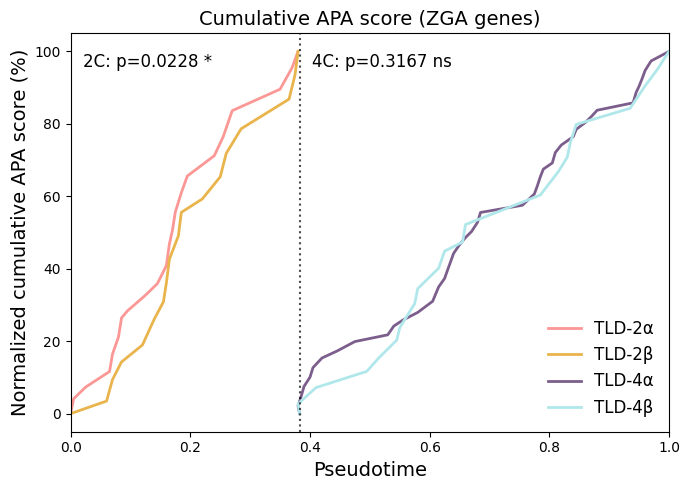


Saved -> IVF_Cumulative_APA_ZGA_Genes_SubgroupNormalized.csv


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

# ========== 全局参数 ==========
BIN_SIZE = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time_orig = 5.5      # IVF 2C/4C 分界原始时间

# ========== 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

if len(sample_to_time) == 0:
    raise ValueError("时间映射为空，无法继续分析。")

all_times = np.array(list(sample_to_time.values()), dtype=float)
t_min_global = all_times.min()
t_max_global = all_times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time_orig - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 读取四个亚群的细胞 ID ==========
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_2C_C1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt")
subgroup_2C_C2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt")
subgroup_4C_D1 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt")
subgroup_4C_D2 = read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt")

# 标签与上文保持一致
subgroups = {
    'TLD-2α': subgroup_2C_C1,
    'TLD-2β': subgroup_2C_C2,
    'TLD-4α': subgroup_4C_D1,
    'TLD-4β': subgroup_4C_D2
}

labels = ['TLD-2α', 'TLD-2β', 'TLD-4α', 'TLD-4β']

# ========== 读取新的 APA z-score 数据（ZGA，无 type 列） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/IVF_ZGA_APA_zscore_summary.txt",
    sep="\t"
)
# 确保列名正确
apa_df.columns = ['cell', 'z_score']   # 文件只有两列
# 按细胞平均（如果有多行，但目前看起来每个细胞一行）
cell_avg = apa_df[['cell', 'z_score']].rename(columns={'z_score': 'value'})
cell_avg['value'] = pd.to_numeric(cell_avg['value'], errors='coerce')
cell_avg = cell_avg.dropna(subset=['value'])

# 只保留在 sample_to_time 中的细胞
cell_avg = cell_avg[cell_avg['cell'].isin(sample_to_time)]
print(f"APA 数据有效细胞数: {len(cell_avg)}")

# ========== 辅助函数：分箱累积曲线（支持跳过第一个 bin） ==========
def build_binned_curve(times, values, bin_size, skip_first=False):
    if len(times) == 0:
        return np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    x = bin_mean['bin'].values
    v = bin_mean['value'].values

    if skip_first and len(v) > 1:
        x = x[1:]
        v = v[1:]

    if len(v) == 0:
        return np.array([]), np.array([])

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum

# ========== 构建曲线（亚群内独立归一化） ==========
curves = {}                # 存储 (x, cum, stage)
bin_stats = {}             # 存储每个亚群每个阶段的 bin 数量、细胞数等

for sg, cells in subgroups.items():
    # 标签已改为 TLD-2α / TLD-2β / TLD-4α / TLD-4β
    if sg.startswith('TLD-2'):
        stage = '2C'
        time_mask = lambda t: t <= min_time_orig
        skip_first = True
    else:
        stage = '4C'
        time_mask = lambda t: t >= min_time_orig
        skip_first = False

    # 筛选存在于 APA 数据中的细胞
    valid_cells = [c for c in cells if c in cell_avg['cell'].values and c in sample_to_time]
    if not valid_cells:
        print(f"警告: {sg} 没有有效 APA 细胞")
        continue

    # 提取该亚群的数据
    sub = cell_avg[cell_avg['cell'].isin(valid_cells)].copy()
    # 添加原始时间
    sub['time_raw'] = sub['cell'].map(sample_to_time)
    sub = sub.dropna(subset=['time_raw'])

    # 按阶段筛选
    mask = time_mask(sub['time_raw'].values)
    sub = sub[mask]
    if sub.empty:
        print(f"警告: {sg} 在 {stage} 阶段没有细胞")
        continue

    # 按时间排序
    sub = sub.sort_values('time_raw')
    times_raw = sub['time_raw'].values.astype(float)
    values = sub['value'].values.astype(float)

    # 亚群内独立归一化
    t_min_sub = times_raw.min()
    t_max_sub = times_raw.max()

    if t_max_sub == t_min_sub:
        if stage == '2C':
            times_norm = np.full_like(times_raw, 0.0, dtype=float)
        else:
            times_norm = np.full_like(times_raw, 1.0, dtype=float)
    else:
        if stage == '2C':
            times_norm = threshold_norm * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)
        else:
            times_norm = threshold_norm + (1 - threshold_norm) * (times_raw - t_min_sub) / (t_max_sub - t_min_sub)

    # 分箱累积曲线
    x, cum = build_binned_curve(times_norm, values, BIN_SIZE, skip_first=skip_first)
    if len(x) == 0:
        print(f"警告: {sg} 累积曲线为空")
        continue

    # 记录 bin 统计信息（原始分箱，未插入起点）
    bin_counts = pd.DataFrame({'time': times_norm, 'value': values})
    bin_counts['bin'] = np.floor(bin_counts['time'] / BIN_SIZE) * BIN_SIZE

    if skip_first:
        bins_keep = np.unique(bin_counts['bin'])[1:] if len(np.unique(bin_counts['bin'])) > 1 else []
        bin_counts = bin_counts[bin_counts['bin'].isin(bins_keep)]

    n_bins = len(np.unique(bin_counts['bin']))
    n_cells = len(bin_counts)
    avg_cells_per_bin = n_cells / n_bins if n_bins > 0 else 0

    bin_stats[sg] = {
        'stage': stage,
        'n_bins': n_bins,
        'n_cells': n_cells,
        'avg_cells_per_bin': avg_cells_per_bin
    }

    curves[sg] = (x, cum, stage)

# 打印每个亚群的 bin 统计
print("\n===== 每个亚群每个阶段的 bin 统计（跳过第一个 bin 后） =====")
for sg in labels:
    if sg in bin_stats:
        stats = bin_stats[sg]
        print(f"{sg} ({stats['stage']}): bins={stats['n_bins']}, cells={stats['n_cells']}, "
              f"avg={stats['avg_cells_per_bin']:.2f}")
    else:
        print(f"{sg}: 无数据")

# 检查曲线完整性
for sg in labels:
    if sg not in curves:
        print(f"错误: {sg} 曲线缺失")

# ========== 统计检验（基于原始数据，不含插入点） ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

p_2c = np.nan
if 'TLD-2α' in curves and 'TLD-2β' in curves:
    x1, y1, _ = curves['TLD-2α']
    x2, y2, _ = curves['TLD-2β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_2c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

p_4c = np.nan
if 'TLD-4α' in curves and 'TLD-4β' in curves:
    x1, y1, _ = curves['TLD-4α']
    x2, y2, _ = curves['TLD-4β']
    _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
    if v1 is not None and len(v1) > 1:
        p_4c = mannwhitneyu(v1, v2, alternative='two-sided').pvalue

print(f"\nTLD-2α vs TLD-2β p = {p_2c}")
print(f"TLD-4α vs TLD-4β p = {p_4c}")

# ========== 绘图（插入起点） ==========
# 配色与上文一致
colors = {
    'TLD-2α': '#fb9795',
    'TLD-2β': '#E9B44C',
    'TLD-4α': '#7c5e8c',
    'TLD-4β': '#b0e7ea'
}

# 全部实线，与上文一致
linestyles = {
    'TLD-2α': '-',
    'TLD-2β': '-',
    'TLD-4α': '-',
    'TLD-4β': '-'
}

fig, ax = plt.subplots(figsize=(7, 5))

for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:  # 4C
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    ax.plot(x_plot, y_plot, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    if np.isnan(p):
        return f"{label}: p=NA (ns)"
    return f"{label}: {format_p_value(p)} {sig_star(p)}"

ax.text(0.02, 0.95, format_p_text("2C", p_2c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)
ax.text(min(threshold_norm + 0.02, 0.98), 0.95, format_p_text("4C", p_4c),
        transform=ax.transAxes, va='top', ha='left', fontsize=12)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative APA score (%)', fontsize=14)
ax.set_title('Cumulative APA score (ZGA genes)', fontsize=14)
ax.set_xlim(0, 1)
ax.legend(loc='lower right', fontsize=12, frameon=False)

plt.tight_layout()
plt.savefig('IVF_Cumulative_APA_ZGA_Genes_SubgroupNormalized.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ========== 保存曲线数据 ==========
curve_records = []
for sg in labels:
    if sg not in curves:
        continue
    x, y, stage = curves[sg]
    if stage == '2C':
        x_plot = np.insert(x, 0, 0.0)
        y_plot = np.insert(y, 0, 0.0)
    else:
        x_plot = np.insert(x, 0, threshold_norm)
        y_plot = np.insert(y, 0, 0.0)
    for xi, yi in zip(x_plot, y_plot):
        curve_records.append([sg, xi, yi])

curve_df = pd.DataFrame(curve_records, columns=["subgroup", "bin", "cumulative_percent"])
curve_df.to_csv("IVF_Cumulative_APA_ZGA_Genes_SubgroupNormalized.csv", index=False)
print("\nSaved -> IVF_Cumulative_APA_ZGA_Genes_SubgroupNormalized.csv")

Number of genes used for cumulative curves: 20146
全局分割点 (threshold_norm): 0.4041
Original p = 0.007466991983700391


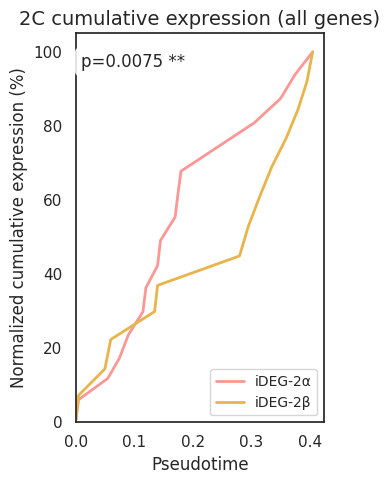

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
sns.set(style="white")

# ========== 固定随机种子 ==========
np.random.seed(42)

# ========== 全局参数 ==========
BIN_SIZE_NORM = 0.005
BIN_WIDTH_SAMPLE = 2
N_SAMPLES = 70
ALPHA = 0.05
min_time = 5.5

# ========== 数据读取与预处理 ==========
gene_file = "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/expressed_genes.txt"
zga_genes = set(pd.read_csv(gene_file, header=None)[0].tolist())

time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt",
    sep="\t", index_col=0
)
pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
pseudo_df['pseudotime'] = pd.to_numeric(pseudo_df['pseudotime'], errors='coerce')
pseudo_df = pseudo_df.dropna(subset=['pseudotime'])
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_zga = expr.loc[expr.index.intersection(zga_genes)].copy()
print(f"Number of genes used for cumulative curves: {len(expr_zga)}")
expr_mean = np.log2(expr_zga + 1).mean(axis=0)
common_cells = [c for c in expr_mean.index if c in cell_to_pseudotime]
expr_mean = expr_mean[common_cells]
times = np.array([cell_to_pseudotime[c] for c in common_cells], dtype=float)
values = expr_mean.values.astype(float)
idx = np.argsort(times)
times, values = times[idx], values[idx]
cell_order = np.array(common_cells)[idx]

t_min_global = times.min()
t_max_global = times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

def convert_cell_name(name):
    if name in common_cells:
        return name
    if name.startswith("IVF-2-"):
        parts = name.split("-")
        return f"IVF.R2C.{parts[2]}.{parts[3]}"
    elif name.startswith("IVF-4-"):
        parts = name.split("-")
        return f"IVF.R4.{parts[2]}.{parts[3]}"
    else:
        return name.replace("-", ".")

def read_ids(filepath):
    with open(filepath) as f:
        raw = [line.strip() for line in f if line.strip()]
    converted = [convert_cell_name(c) for c in raw]
    valid = [c for c in converted if c in common_cells]
    return valid

# 标签改为 iDEG-2α / iDEG-2β / iDEG-4α / iDEG-4β
subgroup_files = {
    'iDEG-2α': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    'iDEG-2β': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    'iDEG-4α': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    'iDEG-4β': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
}

subgroup_cells = {}
for sg, fpath in subgroup_files.items():
    cells = read_ids(fpath)
    subgroup_cells[sg] = cells

cell_to_time = {cell: cell_to_pseudotime[cell] for cell in common_cells if cell in cell_to_pseudotime}
original_cells = {sg: cells[:] for sg, cells in subgroup_cells.items()}

sg1, sg2 = 'iDEG-2α', 'iDEG-2β'

# ========== 累积曲线构建函数（从 (0,0) 开始） ==========
def build_curve_for_group(cells, times, values, cell_order, bin_size, threshold):
    sg_mask = np.isin(cell_order, cells)
    mask = sg_mask & (times <= min_time)
    if np.sum(mask) == 0:
        return np.array([]), np.array([])

    t_sub = times[mask]
    v_sub = values[mask]
    idx_sub = np.argsort(t_sub)
    t_sub = t_sub[idx_sub]
    v_sub = v_sub[idx_sub]

    t_min_sub = t_sub.min()
    t_max_sub = t_sub.max()

    if t_max_sub == t_min_sub:
        t_norm = np.full_like(t_sub, 0.0, dtype=float)
    else:
        t_norm = threshold * (t_sub - t_min_sub) / (t_max_sub - t_min_sub)

    df = pd.DataFrame({'time': t_norm, 'value': v_sub})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    v = bin_mean['value'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    # 使用右边界，并在开头插入 (0,0)
    x = bin_mean['bin'].values + bin_size
    x = np.insert(x, 0, 0.0)
    cum = np.insert(cum, 0, 0.0)
    return x, cum

curves_original = {}
for sg in [sg1, sg2]:
    x, cum = build_curve_for_group(original_cells[sg], times, values, cell_order, BIN_SIZE_NORM, threshold_norm)
    if len(x) > 0:
        curves_original[sg] = (x, cum)

# ========== 统计检验 ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

def calc_p_from_curves(curves_dict, sg1, sg2):
    p = np.nan
    if sg1 in curves_dict and sg2 in curves_dict:
        x1, y1 = curves_dict[sg1]
        x2, y2 = curves_dict[sg2]
        _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
        if v1 is not None and len(v1) > 1:
            p = mannwhitneyu(v1, v2, alternative='two-sided').pvalue
    return p

p_original = calc_p_from_curves(curves_original, sg1, sg2)
print(f"Original p = {p_original}")

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(p):
    if np.isnan(p):
        return "p=NA (ns)"
    return f"{format_p_value(p)} {sig_star(p)}"

# ========== 绘制单一子图：原始累积曲线 ==========
fig, ax = plt.subplots(figsize=(3.5, 5))

# 配色与线型与前面所有图保持一致
colors = {
    'iDEG-2α': '#fb9795',
    'iDEG-2β': '#E9B44C',
    'iDEG-4α': '#7c5e8c',
    'iDEG-4β': '#b0e7ea'
}
linestyles = {
    'iDEG-2α': '-',
    'iDEG-2β': '-',
    'iDEG-4α': '-',
    'iDEG-4β': '-'
}

for sg, (x, y) in curves_original.items():
    ax.plot(x, y, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.set_xlabel('Pseudotime', fontsize=12)
ax.set_ylabel('Normalized cumulative expression (%)', fontsize=12)
ax.set_title('2C cumulative expression (all genes)', fontsize=14)
ax.set_xlim(0, threshold_norm * 1.05)
ax.set_ylim(0, 105)
ax.legend(loc='lower right', fontsize=10)
ax.text(0.02, 0.95, format_p_text(p_original),
        transform=ax.transAxes, va='top', ha='left', fontsize=12,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig('IVF_2C_iDEG_curve.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

Common cells: 102
全局分割点 (threshold_norm): 0.4041
ZGA: 3408 genes
DEPIGs: 3934 genes
ZGA: p = 0.007848171577674446
DEPIGs: p = 0.002915885261815732


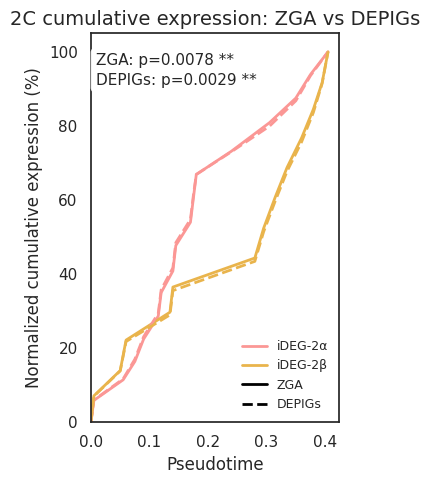

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu
from matplotlib.lines import Line2D

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
sns.set(style="white")

# ========== 固定随机种子 ==========
np.random.seed(42)

# ========== 全局参数 ==========
BIN_SIZE_NORM = 0.005
N_SAMPLES = 70
ALPHA = 0.05
min_time = 5.5

# ========== 读取表达矩阵与伪时间 ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt",
    sep="\t", index_col=0
)
pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
pseudo_df['pseudotime'] = pd.to_numeric(pseudo_df['pseudotime'], errors='coerce')
pseudo_df = pseudo_df.dropna(subset=['pseudotime'])
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

# ========== 两个基因集 ==========
gene_files = {
    'ZGA': "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/IVF_ZGAid.txt",
    'DEPIGs': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_2C_4C_diffEPI_overlap_id.txt"
}

# ========== 共用细胞、时间、阈值 ==========
common_cells = [c for c in expr.columns if c in cell_to_pseudotime]
print(f"Common cells: {len(common_cells)}")

times_all = np.array([cell_to_pseudotime[c] for c in common_cells], dtype=float)
idx = np.argsort(times_all)
times = times_all[idx]
cell_order = np.array(common_cells)[idx]

t_min_global = times.min()
t_max_global = times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

# ========== 分别计算每个基因集的 values ==========
gene_values = {}
for name, fpath in gene_files.items():
    genes = set(pd.read_csv(fpath, header=None)[0].tolist())
    expr_sub = expr.loc[expr.index.intersection(genes)].copy()
    print(f"{name}: {len(expr_sub)} genes")

    expr_mean = np.log2(expr_sub + 1).mean(axis=0)
    values = expr_mean[common_cells].values.astype(float)[idx]
    gene_values[name] = values

# ========== 细胞名转换与亚群读取 ==========
def convert_cell_name(name):
    if name in common_cells:
        return name
    if name.startswith("IVF-2-"):
        parts = name.split("-")
        return f"IVF.R2C.{parts[2]}.{parts[3]}"
    elif name.startswith("IVF-4-"):
        parts = name.split("-")
        return f"IVF.R4.{parts[2]}.{parts[3]}"
    else:
        return name.replace("-", ".")

def read_ids(filepath):
    with open(filepath) as f:
        raw = [line.strip() for line in f if line.strip()]
    converted = [convert_cell_name(c) for c in raw]
    valid = [c for c in converted if c in common_cells]
    return valid

subgroup_files = {
    'iDEG-2α': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    'iDEG-2β': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    'iDEG-4α': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    'iDEG-4β': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
}

subgroup_cells = {sg: read_ids(fpath) for sg, fpath in subgroup_files.items()}
original_cells = {sg: cells[:] for sg, cells in subgroup_cells.items()}

sg1, sg2 = 'iDEG-2α', 'iDEG-2β'

# ========== 累积曲线构建函数（从 (0,0) 开始） ==========
def build_curve_for_group(cells, times, values, cell_order, bin_size, threshold):
    sg_mask = np.isin(cell_order, cells)
    mask = sg_mask & (times <= min_time)

    if np.sum(mask) == 0:
        return np.array([]), np.array([])

    t_sub = times[mask]
    v_sub = values[mask]
    idx_sub = np.argsort(t_sub)
    t_sub = t_sub[idx_sub]
    v_sub = v_sub[idx_sub]

    t_min_sub = t_sub.min()
    t_max_sub = t_sub.max()

    if t_max_sub == t_min_sub:
        t_norm = np.full_like(t_sub, 0.0, dtype=float)
    else:
        t_norm = threshold * (t_sub - t_min_sub) / (t_max_sub - t_min_sub)

    df = pd.DataFrame({'time': t_norm, 'value': v_sub})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    v = bin_mean['value'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    x = bin_mean['bin'].values + bin_size
    x = np.insert(x, 0, 0.0)
    cum = np.insert(cum, 0, 0.0)
    return x, cum

# ========== 统计检验 ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

def calc_p_from_curves(curves_dict, sg1, sg2):
    p = np.nan
    if sg1 in curves_dict and sg2 in curves_dict:
        x1, y1 = curves_dict[sg1]
        x2, y2 = curves_dict[sg2]
        _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
        if v1 is not None and len(v1) > 1:
            p = mannwhitneyu(v1, v2, alternative='two-sided').pvalue
    return p

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(label, p):
    if np.isnan(p):
        return f"{label}: p=NA (ns)"
    return f"{label}: {format_p_value(p)} {sig_star(p)}"

# ========== 构建曲线并计算 p 值 ==========
curves = {}      # (sg, gene_set) -> (x, cum)
p_values = {}    # gene_set -> p

for gene_set in ['ZGA', 'DEPIGs']:
    vals = gene_values[gene_set]
    for sg in [sg1, sg2]:
        x, cum = build_curve_for_group(
            original_cells[sg], times, vals, cell_order, BIN_SIZE_NORM, threshold_norm
        )
        if len(x) > 0:
            curves[(sg, gene_set)] = (x, cum)

    cur_dict = {sg: curves[(sg, gene_set)] for sg in [sg1, sg2] if (sg, gene_set) in curves}
    p_values[gene_set] = calc_p_from_curves(cur_dict, sg1, sg2)
    print(f"{gene_set}: p = {p_values[gene_set]}")

# ========== 绘图 ==========
fig, ax = plt.subplots(figsize=(3.5, 5))

# 颜色 = 亚群，线型 = 基因集
colors = {
    'iDEG-2α': '#fb9795',
    'iDEG-2β': '#E9B44C'
}
linestyles = {
    'ZGA': '-',
    'DEPIGs': '--'
}

for gene_set in ['ZGA', 'DEPIGs']:
    for sg in [sg1, sg2]:
        if (sg, gene_set) not in curves:
            continue
        x, y = curves[(sg, gene_set)]
        ax.plot(x, y, color=colors[sg], linestyle=linestyles[gene_set],
                linewidth=2)

ax.set_xlabel('Pseudotime', fontsize=12)
ax.set_ylabel('Normalized cumulative expression (%)', fontsize=12)
ax.set_title('2C cumulative expression: ZGA vs DEPIGs', fontsize=14)
ax.set_xlim(0, threshold_norm * 1.05)
ax.set_ylim(0, 105)

# 自定义图例：颜色表示亚群，线型表示基因集
legend_elements = [
    Line2D([0], [0], color=colors['iDEG-2α'], lw=2, linestyle='-', label='iDEG-2α'),
    Line2D([0], [0], color=colors['iDEG-2β'], lw=2, linestyle='-', label='iDEG-2β'),
    Line2D([0], [0], color='black', lw=2, linestyle='-', label='ZGA'),
    Line2D([0], [0], color='black', lw=2, linestyle='--', label='DEPIGs')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9, frameon=False)

# p 值文本框：ZGA 与 DEPIGs 上下排列，放左上
p_text = "\n".join([
    format_p_text('ZGA', p_values['ZGA']),
    format_p_text('DEPIGs', p_values['DEPIGs'])
])
ax.text(0.02, 0.95, p_text,
        transform=ax.transAxes, va='top', ha='left', fontsize=11,
        linespacing=1.4,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

plt.tight_layout()
plt.savefig('IVF_2C_expr_ZGA_vs_DEPIGs_curve.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

Number of genes used for cumulative curves: 3408
全局分割点 (threshold_norm): 0.4041
Original p = 0.007848171577674446


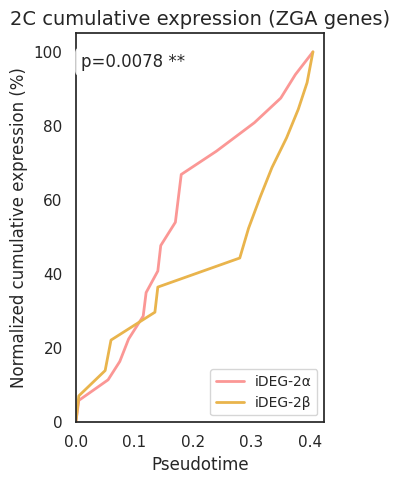

In [30]:
# ZGA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
sns.set(style="white")

# ========== 固定随机种子 ==========
np.random.seed(42)

# ========== 全局参数 ==========
BIN_SIZE_NORM = 0.005
BIN_WIDTH_SAMPLE = 2
N_SAMPLES = 70
ALPHA = 0.05
min_time = 5.5

# ========== 数据读取与预处理 ==========
gene_file = "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/IVF_ZGAid.txt"
zga_genes = set(pd.read_csv(gene_file, header=None)[0].tolist())

time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt",
    sep="\t", index_col=0
)
pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
pseudo_df['pseudotime'] = pd.to_numeric(pseudo_df['pseudotime'], errors='coerce')
pseudo_df = pseudo_df.dropna(subset=['pseudotime'])
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_zga = expr.loc[expr.index.intersection(zga_genes)].copy()
print(f"Number of genes used for cumulative curves: {len(expr_zga)}")
expr_mean = np.log2(expr_zga + 1).mean(axis=0)
common_cells = [c for c in expr_mean.index if c in cell_to_pseudotime]
expr_mean = expr_mean[common_cells]
times = np.array([cell_to_pseudotime[c] for c in common_cells], dtype=float)
values = expr_mean.values.astype(float)
idx = np.argsort(times)
times, values = times[idx], values[idx]
cell_order = np.array(common_cells)[idx]

t_min_global = times.min()
t_max_global = times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

def convert_cell_name(name):
    if name in common_cells:
        return name
    if name.startswith("IVF-2-"):
        parts = name.split("-")
        return f"IVF.R2C.{parts[2]}.{parts[3]}"
    elif name.startswith("IVF-4-"):
        parts = name.split("-")
        return f"IVF.R4.{parts[2]}.{parts[3]}"
    else:
        return name.replace("-", ".")

def read_ids(filepath):
    with open(filepath) as f:
        raw = [line.strip() for line in f if line.strip()]
    converted = [convert_cell_name(c) for c in raw]
    valid = [c for c in converted if c in common_cells]
    return valid

# 标签改为 iDEG-2α / iDEG-2β / iDEG-4α / iDEG-4β
subgroup_files = {
    'iDEG-2α': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    'iDEG-2β': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    'iDEG-4α': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    'iDEG-4β': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
}

subgroup_cells = {}
for sg, fpath in subgroup_files.items():
    cells = read_ids(fpath)
    subgroup_cells[sg] = cells

cell_to_time = {cell: cell_to_pseudotime[cell] for cell in common_cells if cell in cell_to_pseudotime}
original_cells = {sg: cells[:] for sg, cells in subgroup_cells.items()}

sg1, sg2 = 'iDEG-2α', 'iDEG-2β'

# ========== 累积曲线构建函数（从 (0,0) 开始） ==========
def build_curve_for_group(cells, times, values, cell_order, bin_size, threshold):
    sg_mask = np.isin(cell_order, cells)
    mask = sg_mask & (times <= min_time)
    if np.sum(mask) == 0:
        return np.array([]), np.array([])

    t_sub = times[mask]
    v_sub = values[mask]
    idx_sub = np.argsort(t_sub)
    t_sub = t_sub[idx_sub]
    v_sub = v_sub[idx_sub]

    t_min_sub = t_sub.min()
    t_max_sub = t_sub.max()

    if t_max_sub == t_min_sub:
        t_norm = np.full_like(t_sub, 0.0, dtype=float)
    else:
        t_norm = threshold * (t_sub - t_min_sub) / (t_max_sub - t_min_sub)

    df = pd.DataFrame({'time': t_norm, 'value': v_sub})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    v = bin_mean['value'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    # 使用右边界，并在开头插入 (0,0)
    x = bin_mean['bin'].values + bin_size
    x = np.insert(x, 0, 0.0)
    cum = np.insert(cum, 0, 0.0)
    return x, cum

curves_original = {}
for sg in [sg1, sg2]:
    x, cum = build_curve_for_group(original_cells[sg], times, values, cell_order, BIN_SIZE_NORM, threshold_norm)
    if len(x) > 0:
        curves_original[sg] = (x, cum)

# ========== 统计检验 ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 500)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

def calc_p_from_curves(curves_dict, sg1, sg2):
    p = np.nan
    if sg1 in curves_dict and sg2 in curves_dict:
        x1, y1 = curves_dict[sg1]
        x2, y2 = curves_dict[sg2]
        _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
        if v1 is not None and len(v1) > 1:
            p = mannwhitneyu(v1, v2, alternative='two-sided').pvalue
    return p

p_original = calc_p_from_curves(curves_original, sg1, sg2)
print(f"Original p = {p_original}")

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(p):
    if np.isnan(p):
        return "p=NA (ns)"
    return f"{format_p_value(p)} {sig_star(p)}"

# ========== 绘制单一子图：原始累积曲线 ==========
fig, ax = plt.subplots(figsize=(3.5, 5))

# 配色与线型与前面所有图保持一致
colors = {
    'iDEG-2α': '#fb9795',
    'iDEG-2β': '#E9B44C',
    'iDEG-4α': '#7c5e8c',
    'iDEG-4β': '#b0e7ea'
}
linestyles = {
    'iDEG-2α': '-',
    'iDEG-2β': '-',
    'iDEG-4α': '-',
    'iDEG-4β': '-'
}

for sg, (x, y) in curves_original.items():
    ax.plot(x, y, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.set_xlabel('Pseudotime', fontsize=12)
ax.set_ylabel('Normalized cumulative expression (%)', fontsize=12)
ax.set_title('2C cumulative expression (ZGA genes)', fontsize=14)
ax.set_xlim(0, threshold_norm * 1.05)
ax.set_ylim(0, 105)
ax.legend(loc='lower right', fontsize=10)
ax.text(0.02, 0.95, format_p_text(p_original),
        transform=ax.transAxes, va='top', ha='left', fontsize=12,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig('IVF_2C_expr_ZGA_curve.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

Number of genes used for cumulative curves: 2285
全局分割点 (threshold_norm): 0.4041
Original p = 0.00814820694670531


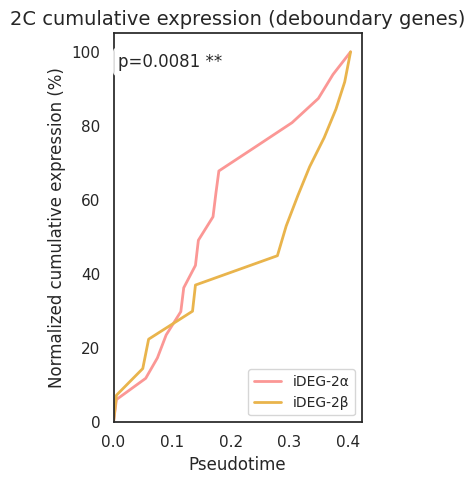

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
sns.set(style="white")

# ========== 固定随机种子 ==========
np.random.seed(42)

# ========== 全局参数 ==========
BIN_SIZE_NORM = 0.005
BIN_WIDTH_SAMPLE = 2
N_SAMPLES = 70
ALPHA = 0.05
min_time = 5.5

# ========== 数据读取与预处理 ==========
gene_file = "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_morula_boundaries_80k_2C_4C_deboundary2gene_id.txt"
zga_genes = set(pd.read_csv(gene_file, header=None)[0].tolist())

time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt",
    sep="\t", index_col=0
)
pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
pseudo_df['pseudotime'] = pd.to_numeric(pseudo_df['pseudotime'], errors='coerce')
pseudo_df = pseudo_df.dropna(subset=['pseudotime'])
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_zga = expr.loc[expr.index.intersection(zga_genes)].copy()
print(f"Number of genes used for cumulative curves: {len(expr_zga)}")
expr_mean = np.log2(expr_zga + 1).mean(axis=0)
common_cells = [c for c in expr_mean.index if c in cell_to_pseudotime]
expr_mean = expr_mean[common_cells]
times = np.array([cell_to_pseudotime[c] for c in common_cells], dtype=float)
values = expr_mean.values.astype(float)
idx = np.argsort(times)
times, values = times[idx], values[idx]
cell_order = np.array(common_cells)[idx]

t_min_global = times.min()
t_max_global = times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

def convert_cell_name(name):
    if name in common_cells:
        return name
    if name.startswith("IVF-2-"):
        parts = name.split("-")
        return f"IVF.R2C.{parts[2]}.{parts[3]}"
    elif name.startswith("IVF-4-"):
        parts = name.split("-")
        return f"IVF.R4.{parts[2]}.{parts[3]}"
    else:
        return name.replace("-", ".")

def read_ids(filepath):
    with open(filepath) as f:
        raw = [line.strip() for line in f if line.strip()]
    converted = [convert_cell_name(c) for c in raw]
    valid = [c for c in converted if c in common_cells]
    return valid

# 标签改为 iDEG-2α / iDEG-2β / iDEG-4α / iDEG-4β
subgroup_files = {
    'iDEG-2α': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    'iDEG-2β': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    'iDEG-4α': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    'iDEG-4β': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
}

subgroup_cells = {}
for sg, fpath in subgroup_files.items():
    cells = read_ids(fpath)
    subgroup_cells[sg] = cells

cell_to_time = {cell: cell_to_pseudotime[cell] for cell in common_cells if cell in cell_to_pseudotime}
original_cells = {sg: cells[:] for sg, cells in subgroup_cells.items()}

sg1, sg2 = 'iDEG-2α', 'iDEG-2β'

# ========== 累积曲线构建函数（从 (0,0) 开始） ==========
def build_curve_for_group(cells, times, values, cell_order, bin_size, threshold):
    sg_mask = np.isin(cell_order, cells)
    mask = sg_mask & (times <= min_time)
    if np.sum(mask) == 0:
        return np.array([]), np.array([])

    t_sub = times[mask]
    v_sub = values[mask]
    idx_sub = np.argsort(t_sub)
    t_sub = t_sub[idx_sub]
    v_sub = v_sub[idx_sub]

    t_min_sub = t_sub.min()
    t_max_sub = t_sub.max()

    if t_max_sub == t_min_sub:
        t_norm = np.full_like(t_sub, 0.0, dtype=float)
    else:
        t_norm = threshold * (t_sub - t_min_sub) / (t_max_sub - t_min_sub)

    df = pd.DataFrame({'time': t_norm, 'value': v_sub})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    v = bin_mean['value'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    # 使用右边界，并在开头插入 (0,0)
    x = bin_mean['bin'].values + bin_size
    x = np.insert(x, 0, 0.0)
    cum = np.insert(cum, 0, 0.0)
    return x, cum

curves_original = {}
for sg in [sg1, sg2]:
    x, cum = build_curve_for_group(original_cells[sg], times, values, cell_order, BIN_SIZE_NORM, threshold_norm)
    if len(x) > 0:
        curves_original[sg] = (x, cum)

# ========== 统计检验 ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 400)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

def calc_p_from_curves(curves_dict, sg1, sg2):
    p = np.nan
    if sg1 in curves_dict and sg2 in curves_dict:
        x1, y1 = curves_dict[sg1]
        x2, y2 = curves_dict[sg2]
        _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
        if v1 is not None and len(v1) > 1:
            p = mannwhitneyu(v1, v2, alternative='two-sided').pvalue
    return p

p_original = calc_p_from_curves(curves_original, sg1, sg2)
print(f"Original p = {p_original}")

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(p):
    if np.isnan(p):
        return "p=NA (ns)"
    return f"{format_p_value(p)} {sig_star(p)}"

# ========== 绘制单一子图：原始累积曲线 ==========
fig, ax = plt.subplots(figsize=(3.5, 5))

# 配色与线型与前面所有图保持一致
colors = {
    'iDEG-2α': '#fb9795',
    'iDEG-2β': '#E9B44C',
    'iDEG-4α': '#7c5e8c',
    'iDEG-4β': '#b0e7ea'
}
linestyles = {
    'iDEG-2α': '-',
    'iDEG-2β': '-',
    'iDEG-4α': '-',
    'iDEG-4β': '-'
}

for sg, (x, y) in curves_original.items():
    ax.plot(x, y, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.set_xlabel('Pseudotime', fontsize=12)
ax.set_ylabel('Normalized cumulative expression (%)', fontsize=12)
ax.set_title('2C cumulative expression (deboundary genes)', fontsize=14)
ax.set_xlim(0, threshold_norm * 1.05)
ax.set_ylim(0, 105)
ax.legend(loc='lower right', fontsize=10)
ax.text(0.02, 0.95, format_p_text(p_original),
        transform=ax.transAxes, va='top', ha='left', fontsize=12,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig('IVF_2C_curve_deboundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

Number of genes used for cumulative curves: 3934
全局分割点 (threshold_norm): 0.4041
Original p = 0.00316502157829311


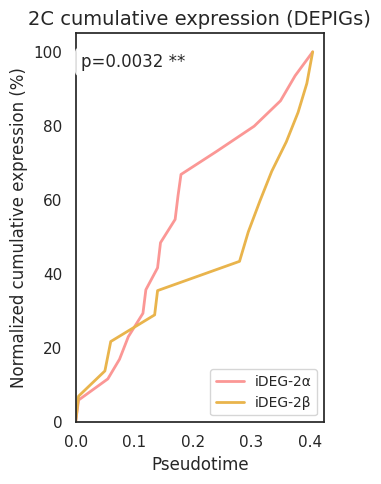

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
sns.set(style="white")

# ========== 固定随机种子 ==========
np.random.seed(42)

# ========== 全局参数 ==========
BIN_SIZE_NORM = 0.005
BIN_WIDTH_SAMPLE = 2
N_SAMPLES = 70
ALPHA = 0.05
min_time = 5.5

# ========== 数据读取与预处理 ==========
gene_file = "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_2C_4C_diffEPI_overlap_id.txt"
zga_genes = set(pd.read_csv(gene_file, header=None)[0].tolist())

time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
# 确保 time 是数值
time_df['time'] = pd.to_numeric(time_df['time'], errors='coerce')
time_df = time_df.dropna(subset=['time'])

sample_to_time = dict(zip(time_df['sample'], time_df['time']))

expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_138cells_TPM.txt",
    sep="\t", index_col=0
)
pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
pseudo_df['pseudotime'] = pd.to_numeric(pseudo_df['pseudotime'], errors='coerce')
pseudo_df = pseudo_df.dropna(subset=['pseudotime'])
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_zga = expr.loc[expr.index.intersection(zga_genes)].copy()
print(f"Number of genes used for cumulative curves: {len(expr_zga)}")
expr_mean = np.log2(expr_zga + 1).mean(axis=0)
common_cells = [c for c in expr_mean.index if c in cell_to_pseudotime]
expr_mean = expr_mean[common_cells]
times = np.array([cell_to_pseudotime[c] for c in common_cells], dtype=float)
values = expr_mean.values.astype(float)
idx = np.argsort(times)
times, values = times[idx], values[idx]
cell_order = np.array(common_cells)[idx]

t_min_global = times.min()
t_max_global = times.max()

if t_max_global == t_min_global:
    raise ValueError("全局时间范围为零，无法计算 threshold_norm。")

threshold_norm = (min_time - t_min_global) / (t_max_global - t_min_global)
print(f"全局分割点 (threshold_norm): {threshold_norm:.4f}")

def convert_cell_name(name):
    if name in common_cells:
        return name
    if name.startswith("IVF-2-"):
        parts = name.split("-")
        return f"IVF.R2C.{parts[2]}.{parts[3]}"
    elif name.startswith("IVF-4-"):
        parts = name.split("-")
        return f"IVF.R4.{parts[2]}.{parts[3]}"
    else:
        return name.replace("-", ".")

def read_ids(filepath):
    with open(filepath) as f:
        raw = [line.strip() for line in f if line.strip()]
    converted = [convert_cell_name(c) for c in raw]
    valid = [c for c in converted if c in common_cells]
    return valid

# 标签改为 iDEG-2α / iDEG-2β / iDEG-4α / iDEG-4β
subgroup_files = {
    'iDEG-2α': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    'iDEG-2β': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    'iDEG-4α': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    'iDEG-4β': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
}

subgroup_cells = {}
for sg, fpath in subgroup_files.items():
    cells = read_ids(fpath)
    subgroup_cells[sg] = cells

cell_to_time = {cell: cell_to_pseudotime[cell] for cell in common_cells if cell in cell_to_pseudotime}
original_cells = {sg: cells[:] for sg, cells in subgroup_cells.items()}

sg1, sg2 = 'iDEG-2α', 'iDEG-2β'

# ========== 累积曲线构建函数（从 (0,0) 开始） ==========
def build_curve_for_group(cells, times, values, cell_order, bin_size, threshold):
    sg_mask = np.isin(cell_order, cells)
    mask = sg_mask & (times <= min_time)
    if np.sum(mask) == 0:
        return np.array([]), np.array([])

    t_sub = times[mask]
    v_sub = values[mask]
    idx_sub = np.argsort(t_sub)
    t_sub = t_sub[idx_sub]
    v_sub = v_sub[idx_sub]

    t_min_sub = t_sub.min()
    t_max_sub = t_sub.max()

    if t_max_sub == t_min_sub:
        t_norm = np.full_like(t_sub, 0.0, dtype=float)
    else:
        t_norm = threshold * (t_sub - t_min_sub) / (t_max_sub - t_min_sub)

    df = pd.DataFrame({'time': t_norm, 'value': v_sub})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    bin_mean = (
        df.groupby('bin')['value']
        .mean()
        .reset_index()
        .sort_values('bin')
    )

    v = bin_mean['value'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    # 使用右边界，并在开头插入 (0,0)
    x = bin_mean['bin'].values + bin_size
    x = np.insert(x, 0, 0.0)
    cum = np.insert(cum, 0, 0.0)
    return x, cum

curves_original = {}
for sg in [sg1, sg2]:
    x, cum = build_curve_for_group(original_cells[sg], times, values, cell_order, BIN_SIZE_NORM, threshold_norm)
    if len(x) > 0:
        curves_original[sg] = (x, cum)

# ========== 统计检验 ==========
def downsample_curves(x1, y1, x2, y2, n_samples):
    x_min = max(x1.min(), x2.min())
    x_max = min(x1.max(), x2.max())

    if x_min >= x_max:
        return None, None, None

    common = np.linspace(x_min, x_max, 400)
    f1 = interp1d(x1, y1, kind='previous', fill_value='extrapolate')
    f2 = interp1d(x2, y2, kind='previous', fill_value='extrapolate')

    v1_full = f1(common)
    v2_full = f2(common)

    if len(common) > n_samples:
        idx_s = np.linspace(0, len(common) - 1, n_samples, dtype=int)
        common_sub = common[idx_s]
        v1_sub = v1_full[idx_s]
        v2_sub = v2_full[idx_s]
    else:
        common_sub = common
        v1_sub = v1_full
        v2_sub = v2_full

    return common_sub, v1_sub, v2_sub

def calc_p_from_curves(curves_dict, sg1, sg2):
    p = np.nan
    if sg1 in curves_dict and sg2 in curves_dict:
        x1, y1 = curves_dict[sg1]
        x2, y2 = curves_dict[sg2]
        _, v1, v2 = downsample_curves(x1, y1, x2, y2, N_SAMPLES)
        if v1 is not None and len(v1) > 1:
            p = mannwhitneyu(v1, v2, alternative='two-sided').pvalue
    return p

p_original = calc_p_from_curves(curves_original, sg1, sg2)
print(f"Original p = {p_original}")

# ========== p 值格式化（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def sig_star(p):
    if np.isnan(p):
        return "ns"
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if np.isnan(p):
        return "NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def format_p_text(p):
    if np.isnan(p):
        return "p=NA (ns)"
    return f"{format_p_value(p)} {sig_star(p)}"

# ========== 绘制单一子图：原始累积曲线 ==========
fig, ax = plt.subplots(figsize=(3.5, 5))

# 配色与线型与前面所有图保持一致
colors = {
    'iDEG-2α': '#fb9795',
    'iDEG-2β': '#E9B44C',
    'iDEG-4α': '#7c5e8c',
    'iDEG-4β': '#b0e7ea'
}
linestyles = {
    'iDEG-2α': '-',
    'iDEG-2β': '-',
    'iDEG-4α': '-',
    'iDEG-4β': '-'
}

for sg, (x, y) in curves_original.items():
    ax.plot(x, y, color=colors[sg], linestyle=linestyles[sg],
            linewidth=2, label=sg)

ax.set_xlabel('Pseudotime', fontsize=12)
ax.set_ylabel('Normalized cumulative expression (%)', fontsize=12)
ax.set_title('2C cumulative expression (DEPIGs)', fontsize=14)
ax.set_xlim(0, threshold_norm * 1.05)
ax.set_ylim(0, 105)
ax.legend(loc='lower right', fontsize=10)
ax.text(0.02, 0.95, format_p_text(p_original),
        transform=ax.transAxes, va='top', ha='left', fontsize=12,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig('IVF_2C_original_curve_DEPIGs.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [96]:
#import random
#import os
#import numpy as np
#
## 固定所有随机种子
#def set_seed(seed=42):
#    random.seed(seed)
#    np.random.seed(seed)
#    os.environ['PYTHONHASHSEED'] = str(seed)  # 控制 Python 哈希随机化
#    os.environ['PYTHONHASHSEED'] = str(seed)  # 控制 Python 哈希随机化
#    # 如果使用 tensorflow 或 torch，也需要设置，但此处未用
#
#set_seed(42)